# 1-board: terminal-chain

Grade the terminal taps, the rail tap, the bias node and the ADC reference against the meter, so a count on any voltage channel is a known number of volts, and read the converter's own linearity off the rail tap on a fine grid.

## Purpose

The board reads the two motor terminals through dividers returned to a bias node, the supply rail through a third divider to ground, and converts all of them on one ADC whose reference is the 3.3 V regulator. Back-EMF, the voltage a spinning motor generates, the winding resistance, the undervoltage trip and the rail fold all come through these channels. The board registry carries the dividers as 6k4 over 1k6, a ratio of 5, and the bias node as 430 over 100 from the 3.3 V rail, which is 0.623 V or 773 counts. From those, a count of tap difference is 4.028 mV at the terminals and a count of the rail tap is 4.028 mV of rail. The resistors are 1 % parts and the regulator is not a reference, so the nominal is a starting point.

This experiment grades each channel against the meter on DC laps, where the terminals and the rail sit at steady voltages, reads the ADC's reference through the chip's own 1.2 V reference, and walks the rail tap over a fine grid of levels so the converter's own linearity shows in the residual. Every raw channel goes through the same converter, so that residual belongs to every count the board produces, and the current-scale notebook has a step in its series laps that this residual bears on.

## Procedure

`capture.py` runs one pass per argument. The bare 5 ohm load is on the motor terminals throughout, the board runs the experiment image on the DPS behind the dev board's feed diode, and the DMM is on DC V with its Bluetooth log running for every pass but the last. The meter stayed on its manual 20 V range, 1 mV steps, for all of them. A first `load` pass on autorange left a stale-digit packet at every range change and was discarded, so no range transitions are in this data.

The three lap passes are the DC laps of current-scale. A lap is one `osc-lab sweep` at a supply level, a one second torque-off rest, 100 % duty for three seconds one way, a two second rest, and three seconds the other way, at the levels 3.3, 3.7, 4.2, 4.5, 5.0, 5.5, 7.2 and 7.6 V, the DPS trimmed until the board's own rail tap reads each level. At 100 % duty the bridge does not switch, so the terminals and the rail are DC and a meter reads the same thing the chip samples.

1. `capture.py load`: the meter across the load, MOT_A to MOT_B. The difference of the two taps should read this, and it is free of the bias node.
2. `capture.py tap_a`: the meter from MOT_A to GND, the absolute voltage one tap reads against the bias node. In the laps that drive A high the meter reads the terminal near the rail. In the laps that drive A low it reads the return path's drop, the low switch and the shunt, a few hundred millivolts. In the rests it reads the bias node itself, since the terminal floats to it through the divider.
3. `capture.py rail`: the meter from VSYS to GND, the rail behind the feed diode, at rest and sagging under each lap.
4. `capture.py rail-fine`: the same probes, no laps. The rail walks up from 3.7 to 8.0 V in 20 mV steps, 216 points. The DPS is set to the level plus 0.25 V for the diode and not trimmed, held 1.5 s, then a 250 ms torque-off stream of 5000 rows is taken with the 1.2 V reference in every row. The meter is the x axis and the rail tap the reading. The walk goes up only, since a DPS step down resets the board.
5. `capture.py vdd`: no meter. A three second torque-off stream at each of the eight levels with the 1.2 V reference in every row. The ADC's reference is VDD, so a count is VDD / 4096 and the 1.2 V reference reads lower as VDD rises, which gives VDD = 1.2 V x 4096 / `vref_raw`. This pass was recorded in an earlier sitting on the board's canonical image, which its `meta.json` shows in the host sha and the seek values. A torque-off rest reads the same channels on either image.

## Data

Five folders under the capture, `load`, `tap_a`, `rail`, `rail-fine` and `vdd`.

- `levels.csv`: one row per level. For the lap passes and `vdd`, `k`, `load`, `volts_set` the rail asked for, `dps_read` the DPS output that reached it, `vsys_read` the rail the board read at rest before the lap, `t_start` and `t_end` the host time of the sweep, `folder`. For `rail-fine` there is no trim, so `dps_read` is the set point plus 0.25 V and `vsys_read` is replaced by `t_set`, the host time the DPS set point was written.
- `dmm.csv`: the meter's log through the pass, `t_host`, `function`, `value` in volts, `raw` the packet. Not in `vdd`.
- `laps/<k>/sweep.csv` and `meta.json` in the lap passes: the rest and the two directions at that level, one row per control tick at 20 kHz, the raw channels in counts. The lap rows do not carry `vref_raw`.
- `rest-<v>V/sweep.csv` and `meta.json` in `rail-fine` and `vdd`: a torque-off stream, segment 0, with `vref_raw` in every row. The sweep tool appends a tiny 5 % rung after it, which is not used.

### levels.csv

The rail asked for and the rail read at rest in the four trimmed passes. The fine pass has no trim and no rest reading in its `levels.csv`, so it is summarized in a line.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, boards, laps, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colors
COLOR = {"load": BLUE, "tap_a": ORANGE, "rail": INK, "rail-fine": INK, "vdd": MUTED}   # one color per pass, fixed through the notebook
MARK = {1: "o", -1: "^"}                                                 # the direction as the marker shape, forward filled, reverse open
BOARD = boards.BOARDS[boards.DEFAULT]                                    # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / BOARD.key / "terminal-chain" / "capture-1").resolve()
LAP_PASSES = ["load", "tap_a", "rail"]
PASSES = LAP_PASSES + ["rail-fine", "vdd"]
print(BOARD.key, "from", results.rel(CAPTURE))
print(f"nominal: taps and rail {BOARD.div_ratio:.0f} to 1 on a {BOARD.vdd_mv / 1e3:.1f} V reference = {1 / BOARD.v_term_per_count:.2f} counts per volt, "
      f"{BOARD.v_term_per_count * 1e3:.3f} mV per count; bias node {BOARD.vb_nom_v:.4f} V = {BOARD.bias_nom_counts} counts")

dev-v006-2A-D from telemetry/dev-v006-2A-D/terminal-chain/capture-1
nominal: taps and rail 5 to 1 on a 3.3 V reference = 248.24 counts per volt, 4.028 mV per count; bias node 0.6226 V = 773 counts


,k,load,volts_set,dps_read,vsys_read,t_start,t_end,folder,trim_mv
0,0,bare,3.300,3.580,3.310,1793059264.741,1793059276.056,laps/0,10.000
1,1,bare,3.700,3.950,3.684,1793059279.986,1793059291.306,laps/1,-16.000
2,2,bare,4.200,4.450,4.194,1793059295.236,1793059306.559,laps/2,-6.000
3,3,bare,4.500,4.750,4.483,1793059310.490,1793059321.795,laps/3,-17.000
4,4,bare,5.000,5.250,4.986,1793059325.729,1793059337.085,laps/4,-14.000
5,5,bare,5.500,5.750,5.481,1793059341.016,1793059352.366,laps/5,-19.000
6,6,bare,7.200,7.487,7.229,1793059360.227,1793059371.530,laps/6,29.000
7,7,bare,7.600,7.889,7.624,1793059379.394,1793059390.694,laps/7,24.000


,k,load,volts_set,dps_read,t_set,t_start,t_end,folder
0,0,none,3.700,3.950,1793059411.671,1793059414.884,1793059415.562,rest-3.70V
1,1,none,3.720,3.970,1793059415.562,1793059418.875,1793059419.553,rest-3.72V
2,2,none,3.740,3.990,1793059419.553,1793059422.768,1793059423.448,rest-3.74V
3,3,none,3.760,4.010,1793059423.448,1793059426.660,1793059427.338,rest-3.76V
4,4,none,3.780,4.030,1793059427.338,1793059430.550,1793059431.228,rest-3.78V


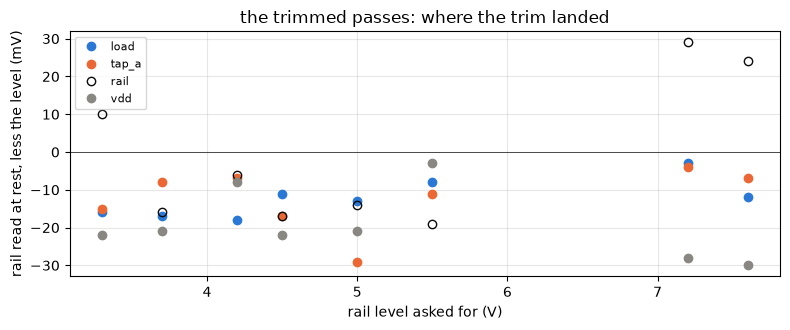

fine pass: 216 points from 3.7 to 8.0 V, step 0.02 V, 3.89 s per point, the DPS a fixed 250 mV over the level


In [2]:
levels = {p: pd.read_csv(CAPTURE / p / "levels.csv") for p in PASSES}     # one frame per pass
for p in LAP_PASSES + ["vdd"]:
    levels[p]["trim_mv"] = (levels[p]["vsys_read"] - levels[p]["volts_set"]) * 1e3   # how far the trim landed from the level
show(levels["rail"], n=None)
show(levels["rail-fine"])
fig, ax = plt.subplots(figsize=(8, 3.4))
for p in LAP_PASSES + ["vdd"]:
    ax.plot(levels[p]["volts_set"], levels[p]["trim_mv"], "o", color=COLOR[p], mfc=COLOR[p] if p != "rail" else "none", label=p)
ax.axhline(0, color=INK, lw=0.5); ax.set_xlabel("rail level asked for (V)"); ax.set_ylabel("rail read at rest, less the level (mV)")
ax.set_title("the trimmed passes: where the trim landed"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
f = levels["rail-fine"]
print("fine pass:", len(f), "points from", f["volts_set"].min(), "to", f["volts_set"].max(), "V, step", round(f["volts_set"].diff().median(), 3), "V,",
      f"{(f['t_end'] - f['t_set']).median():.2f} s per point, the DPS a fixed {((f['dps_read'] - f['volts_set']) * 1e3).median():.0f} mV over the level")

Every trimmed lap sits within 30 mV of its level, as in current-scale, so the levels can be read as the rails they name. The fine pass has 216 points at 20 mV spacing, each about 3.9 s long, with the DPS a fixed 250 mV over the level.

### dmm.csv

The meter's log through each pass. In the lap passes each lap's sweep is shaded. In the fine pass the log is a staircase of 216 steps.

load      packets: 252, functions: ['DC V'], range byte: ['23f0'], interval 0.584 s
tap_a     packets: 244, functions: ['DC V'], range byte: ['23f0'], interval 0.585 s
rail      packets: 268, functions: ['DC V'], range byte: ['23f0'], interval 0.585 s
rail-fine packets: 1684, functions: ['DC V'], range byte: ['23f0'], interval 0.585 s


,t_host,function,value,raw,t
0,16:55:58.115,DC V,0.591,23f000004f02,0.000
1,16:55:58.698,DC V,0.591,23f000004f02,0.584
2,16:55:59.285,DC V,0.591,23f000004f02,1.170
3,16:55:59.674,DC V,0.591,23f000004f02,1.560
4,16:56:00.259,DC V,0.591,23f000004f02,2.145


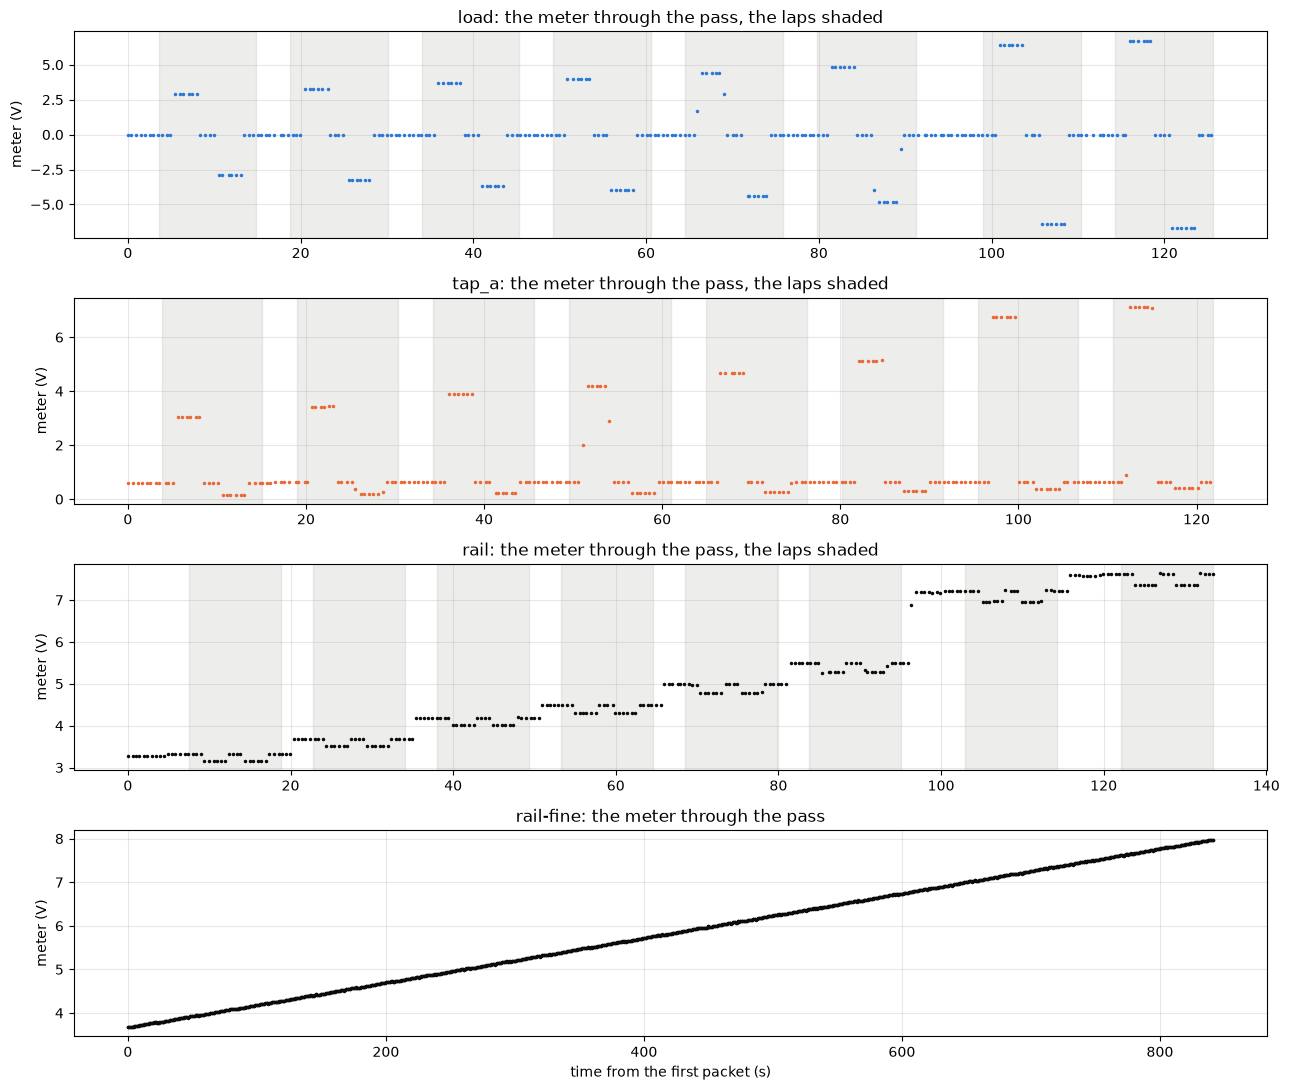

In [3]:
dmm = {p: b41t.load(CAPTURE / p / "dmm.csv") for p in LAP_PASSES + ["rail-fine"]}   # one frame per pass: t_host, function, value, raw
for p in dmm:
    print(f"{p:9s} packets: {len(dmm[p])}, functions: {dmm[p]['function'].unique().tolist()}, range byte: {dmm[p]['raw'].str[:4].unique().tolist()}, "
          f"interval {np.median(np.diff(dmm[p]['t_host'])):.3f} s")
show(dmm["tap_a"])
fig, ax = plt.subplots(4, 1, figsize=(13, 11))
for a, p in zip(ax, dmm):
    d = dmm[p]
    a.plot(d["t"], d["value"], ".", ms=3, color=COLOR[p])                  # every packet
    if p in LAP_PASSES:
        for _, L in levels[p].iterrows():                                 # shade each lap's sweep window
            a.axvspan(L["t_start"] - d["t_host"].iloc[0], L["t_end"] - d["t_host"].iloc[0], color=MUTED, alpha=0.15)
    a.set_ylabel("meter (V)"); a.set_title(f"{p}: the meter through the pass" + (", the laps shaded" if p in LAP_PASSES else "")); a.grid(alpha=0.3)
ax[-1].set_xlabel("time from the first packet (s)")
plt.tight_layout(); plt.show()

The `load` pass reads zero in the rests and the lap voltage each way, positive then negative, like the current in current-scale. The `tap_a` pass reads about 0.62 V in every rest, the bias node, a terminal voltage near the rail in one direction and a few hundred millivolts in the other, so nothing in it flips sign. The `rail` pass reads the rail at every moment, with a dip of a few hundred millivolts under each lap. The fine pass climbs 4.3 V in 216 steps over 14 minutes. One range byte in every pass, so the meter never changed range.

### laps/K/sweep.csv and meta.json

One lap, the 7.6 V level of the `rail` pass. The current channel, the two terminal taps and the rail tap over the rest and the two directions.

segments: {0: 20000, 1: 60000, 2: 60000} | schedule: ['100@3000'] | baseline ms: 1000 | rest ms: 2000 | vref_raw in the lap rows: False


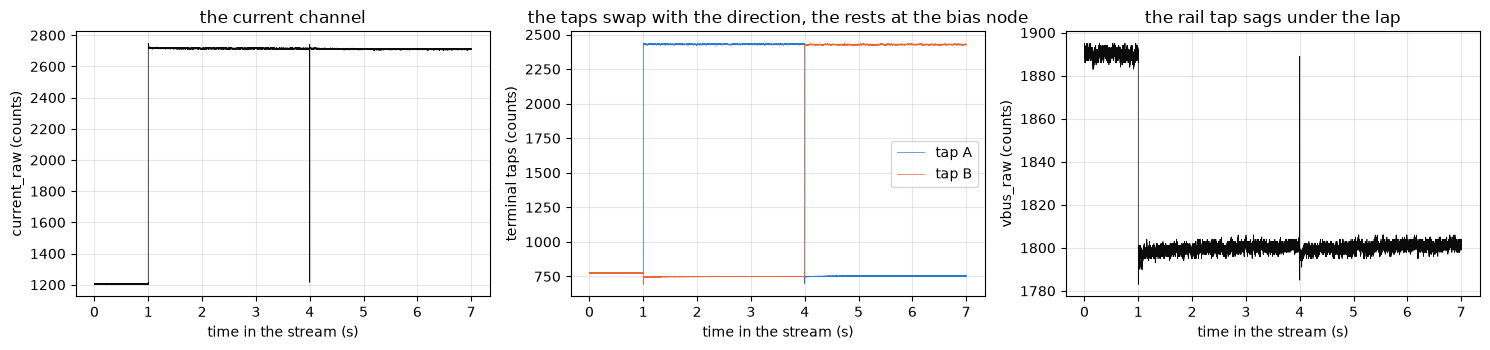

missing rows per lap: {'load': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0}, 'tap_a': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0}, 'rail': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0}}


In [4]:
def lap_folder(p, k):
    return CAPTURE / p / levels[p][levels[p]["k"] == k]["folder"].iloc[0]

df, meta = tel.load(lap_folder("rail", 7), BOARD)      # checks the sense block against the board entry
print("segments:", df["seg"].value_counts().sort_index().to_dict(), "| schedule:", meta["schedule"], "| baseline ms:", meta["baseline_ms"],
      "| rest ms:", meta["rest_ms"], "| vref_raw in the lap rows:", bool(df["vref_raw"].notna().any()))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ts = np.arange(len(df)) / meta["tick_hz"]                  # time through the stream; the 2 s rest between the directions is not streamed
ax[0].plot(ts, df["current_raw"], lw=0.5, color=COLOR["rail"]); ax[0].set_ylabel("current_raw (counts)"); ax[0].set_title("the current channel")
ax[1].plot(ts, df["vmotor_a"], lw=0.5, color=BLUE, label="tap A"); ax[1].plot(ts, df["vmotor_b"], lw=0.5, color=ORANGE, label="tap B")
ax[1].set_ylabel("terminal taps (counts)"); ax[1].legend(); ax[1].set_title("the taps swap with the direction, the rests at the bias node")
ax[2].plot(ts, df["vbus_raw"], lw=0.5, color=COLOR["rail"]); ax[2].set_ylabel("vbus_raw (counts)"); ax[2].set_title("the rail tap sags under the lap")
for a in ax:
    a.set_xlabel("time in the stream (s)"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
missing = {p: {int(L["k"]): int(tel.gaps(tel.load(CAPTURE / p / L["folder"])[0]).sum()) for _, L in levels[p].iterrows()} for p in LAP_PASSES}
print("missing rows per lap:", missing)

The stream holds the rest and the two directions, seven seconds, and the two second rest between the directions is not in it. The taps swap with the direction and sit together at the bias node in the rest, the rail tap drops about 90 counts under the lap and comes back, and the current channel reads the same current both ways. No lap of any pass dropped a row.

### rest-V/sweep.csv and meta.json

One point of the fine pass and one rest of the `vdd` pass, the rail tap and the reference row by row. The thing to see is how steady each channel is inside a point.

rail-fine, 5.00 V: rest rows 5000, vbus_raw 1238.32 sd 1.18, vref_raw 1492.20 sd 1.26, missing rows 0
vdd, 7.6 V: rest rows 60000, vbus_raw 1881.05 sd 1.53, vref_raw 1490.49 sd 1.29, missing rows 0


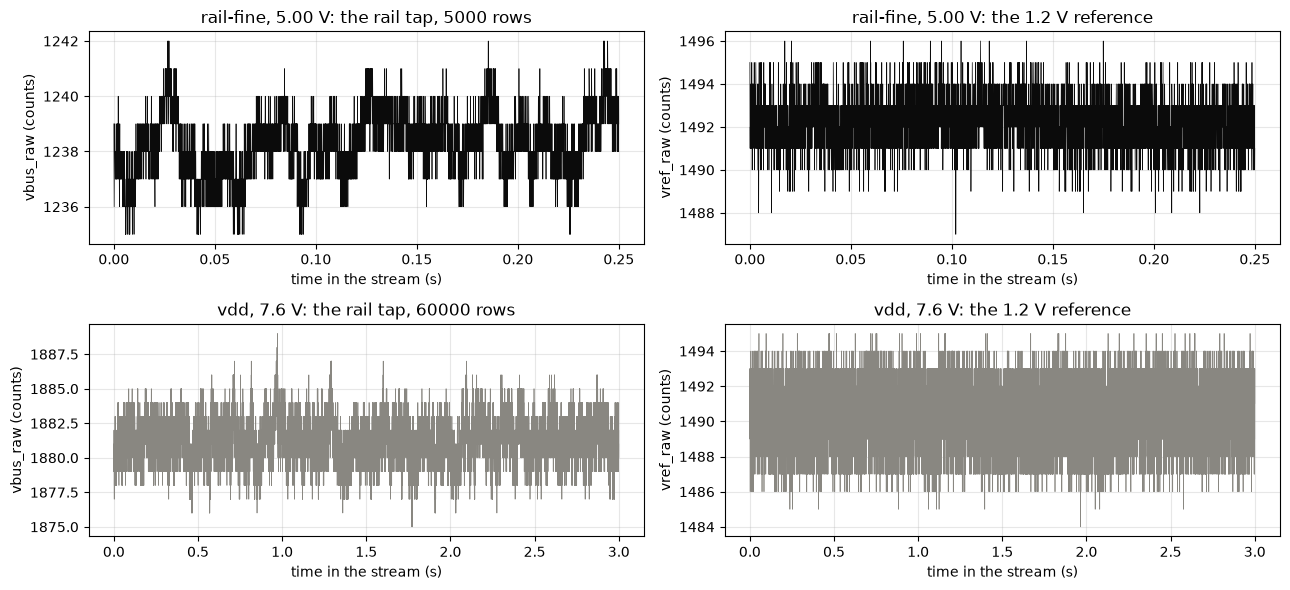

In [5]:
fine_folder = lambda v: CAPTURE / "rail-fine" / f"rest-{v:.2f}V"
vdd_folder = lambda v: CAPTURE / "vdd" / f"rest-{v:g}V"
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for row, (name, folder) in enumerate([("rail-fine, 5.00 V", fine_folder(5.00)), ("vdd, 7.6 V", vdd_folder(7.6))]):
    d, m = tel.load(folder, BOARD); b = d[d["seg"] == 0]
    ax[row, 0].plot(b["t"], b["vbus_raw"], lw=0.5, color=COLOR["rail-fine" if row == 0 else "vdd"]); ax[row, 0].set_ylabel("vbus_raw (counts)")
    ax[row, 1].plot(b["t"], b["vref_raw"], lw=0.5, color=COLOR["rail-fine" if row == 0 else "vdd"]); ax[row, 1].set_ylabel("vref_raw (counts)")
    ax[row, 0].set_title(f"{name}: the rail tap, {len(b)} rows"); ax[row, 1].set_title(f"{name}: the 1.2 V reference")
    print(f"{name}: rest rows {len(b)}, vbus_raw {b['vbus_raw'].mean():.2f} sd {b['vbus_raw'].std():.2f}, vref_raw {b['vref_raw'].mean():.2f} sd {b['vref_raw'].std():.2f}, "
          f"missing rows {int(tel.gaps(d).sum())}")
for a in ax.ravel():
    a.set_xlabel("time in the stream (s)"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Both channels sit within a couple of counts of their mean for the whole stream, the rest-noise floors. A 5000 row point pins the rail tap's mean to a few hundredths of a count, which is the resolution the fine grid rests on.

## Method

Each lap gives one point per direction. The chip's reading is the mean of the raw column over the settled part of the lap, leaving out the first 2 ms, as in current-scale. The meter's reading is the median of its packets while that direction drove. The two have to be lined up, and the meter log is not on the sweep's clock.

For the `load` pass the meter flips sign with the direction, so the driven stretches are found in the log itself, as `oscnb.laps.table` does for the current. The `tap_a` and `rail` passes never read zero, so for them I join by time instead. `levels.csv` carries the host time the sweep was started, and the stream begins a fraction of a second after that, once the process has started and the telemetry burst is armed. I measure that offset on the `load` pass, where the sign flips mark the edges of the segments, and apply it to the other two. The windows are then the stream's layout, one second of rest, three seconds one way, two seconds of rest, three seconds the other way, with the meter's lag from the dmm experiment taken out and half a second of margin inside each edge, since a packet near an edge can carry a reading from either side. The rest reading is the median of the packets just before the drive opens and of the rest between the directions.

For the fine pass each point is its own window. The meter packets from 0.6 s after the DPS set point was written to the end of the stream are taken, six to eight per point, and their median is the meter's reading. The median matters there, since the DPS takes about a second to move and the first packet or two in the window can still read the previous level.

The models are lines. For the terminal difference, the counts between the taps, $n_{AB} = |tap_A - tap_B|$, against the meter's volts $V$,

$$n_{AB} = c + k \, V$$

where $k$ is the scale in counts per volt, nominally 248.24, and $c$ an offset in counts. For the single tap, the registry's formula $V_A = r \, tap_A - (r - 1) \, V_B$ with $r = 5$ and $V_B$ the bias node, read in counts from the rest of the same recording, against the meter on the high-side laps. If the bias node moves under drive, that formula with the rest value is off by $(r - 1)$ times the move, and the low-side laps read the same move from the other side. For the rail, the tap's code against the meter at rest and under the lap, and the sag under the lap against the lap current from the current-scale result. On the fine grid the same line, code against the meter, over 216 points, and then the residual against the code itself. The divider and the meter are linear far below a count over this range, so whatever shape the residual has that follows the code is the converter's.

The residual on the fine grid is written out as a map, one row per point, so the current-scale series laps can be corrected by it. Those laps sit between codes 1467 and 1782 and cross 1536, and their step between the 4.5 V and 5.0 V levels is measured here before and after the map is subtracted, by interpolation, from the lap's code and from its zero.

The reference is read from the `vdd` pass and from the reference rows of the fine pass. With it the rail tap can be converted ratiometrically, with the measured VDD in place of the nominal 3.3 V, and the two conversions are compared.

### Stage 0, rest-noise and current-scale values carried in

In [6]:
DMM = results.read("0-instruments", "dmm")                              # the meter's lag and its class on the 20 V range
PR = results.read("0-instruments", "power-resistors")                   # the bare load's value
RN = results.read("1-board", "rest-noise", pair=BOARD.key)              # the floors of each channel at rest
CS = results.read("1-board", "current-scale", pair=BOARD.key)           # counts per amp and the in-drive offset, for the lap currents
LAG = DMM["lag_s"]["value"]
print(f"meter lag {LAG * 1e3:.0f} ms ({DMM['lag_s']['lo'] * 1e3:.0f} to {DMM['lag_s']['hi'] * 1e3:.0f}), packet interval {DMM['packet_interval_s']['value']:.2f} s; class on the 20 V range {DMM['accuracy']['dc_v_22v']['pct']['value']} % + {DMM['accuracy']['dc_v_22v']['fixed']['value'] * 1e3:.0f} mV")
print(f"bare load {PR['bare']['r_cold']['value']:.3f} ohm")
print(f"rest floors: taps {RN['tap_a_noise']['value']:.2f} and {RN['tap_b_noise']['value']:.2f}, rail {RN['rail_noise']['value']:.2f} "
      f"({RN['rail_noise']['lo']:.2f} to {RN['rail_noise']['hi']:.2f}), vref {RN['vref_noise']['value']:.2f} counts rms; VDD {RN['vdd_v']['value']:.3f} V from 3.7 V up")
print(f"current chain {CS['counts_per_a']['value']:.1f} counts/A, in-drive offset {CS['drive_offset_counts']['value']:+.1f} counts, rest zero {CS['rest_zero_counts']['value']:.0f}")

def lap_amps(current_raw, zero):
    return (np.asarray(current_raw, float) - zero - CS["drive_offset_counts"]["value"]) / CS["counts_per_a"]["value"]

meter lag 20 ms (-81 to 202), packet interval 0.58 s; class on the 20 V range 0.1 % + 2 mV
bare load 5.092 ohm
rest floors: taps 0.61 and 0.65, rail 1.26 (1.05 to 1.51), vref 1.28 counts rms; VDD 3.292 V from 3.7 V up
current chain 1135.0 counts/A, in-drive offset +5.3 counts, rest zero 1206


### The stream's offset from the host time

Measured on the `load` pass. Each lap has four edges in the meter log, rest to drive, drive to rest, rest to the other drive, and back. Each edge falls between two packets, and the stream's layout says where that edge sits in the stream, at 1, 4, 6 and 9 s. The midpoint of the two packets less the layout time is one estimate of the offset, and the figure shows all thirty-two.

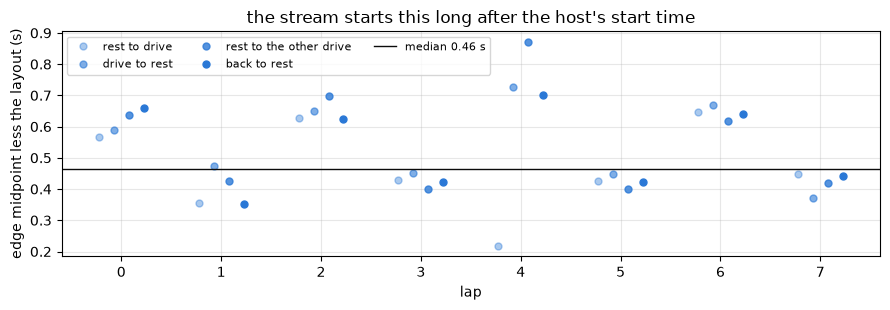

offset: median 0.463 s, mean 0.526, sd 0.144 over 32 edges; packets 0.58 s apart


In [7]:
EDGES = [(1.0, "rest to drive"), (4.0, "drive to rest"), (6.0, "rest to the other drive"), (9.0, "back to rest")]   # the stream's layout
rows = []
d = dmm["load"]
for _, L in levels["load"].iterrows():
    w = d[(d["t_host"] >= L["t_start"]) & (d["t_host"] <= L["t_end"])]
    tt = (w["t_host"] - LAG - L["t_start"]).to_numpy(); v = w["value"].to_numpy()        # packet times from the host start, lag taken out
    state = np.where(np.abs(v) < laps.DRIVEN_FRACTION * np.abs(v).max(), 0, np.sign(v)).astype(int)   # rest, forward or reverse per packet
    for i, (at, name) in zip(np.flatnonzero(np.diff(state) != 0), EDGES):                  # the edge lies between packets i and i+1
        rows.append({"k": int(L["k"]), "edge": name, "offset": (tt[i] + tt[i + 1]) / 2 - at, "gap": tt[i + 1] - tt[i]})
edges = pd.DataFrame(rows)
OFFSET = float(edges["offset"].median())
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (_, name) in enumerate(EDGES):
    g = edges[edges["edge"] == name]
    ax.plot(g["k"] + 0.15 * (i - 1.5), g["offset"], "o", ms=5, color=COLOR["load"], alpha=0.4 + 0.2 * i, label=name)
ax.axhline(OFFSET, color=INK, lw=1, label=f"median {OFFSET:.2f} s")
ax.set_xlabel("lap"); ax.set_ylabel("edge midpoint less the layout (s)"); ax.set_title("the stream starts this long after the host's start time"); ax.legend(fontsize=8, ncol=3); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"offset: median {OFFSET:.3f} s, mean {edges['offset'].mean():.3f}, sd {edges['offset'].std():.3f} over {len(edges)} edges; packets {edges['gap'].median():.2f} s apart")

The stream starts about 0.46 s after the host's start time, with the thirty-two edges scattered by 0.14 s, a quarter of the packet interval, which is the resolution the meter allows. A half second margin inside each three second window keeps every packet clear of its edges.

### The lap tables

One row per lap and direction for each pass. The `load` pass joins the meter by its driven stretches. The `tap_a` and `rail` passes join by time, and as a check the time join is run on the `load` pass as well and compared with the stretch join.

In [8]:
LAYOUT = {1: (1.0, 4.0), 2: (6.0, 9.0)}          # stream segment -> seconds from the stream's start; segment 0 is the first second
MARGIN = 0.5

def meter_in(d, t0, a, b, margin=MARGIN):
    # the meter packets between a and b seconds after the stream start t0, the lag taken out, inside the margin
    return d[(d["t_host"] - LAG >= t0 + a + margin) & (d["t_host"] - LAG <= t0 + b - margin)]["value"]

def table_by_time(p):
    rows = []
    d = dmm[p]
    for _, L in levels[p].iterrows():
        df, meta = tel.load(CAPTURE / p / L["folder"], BOARD)
        b = tel.baseline(df)                                                    # the second half of the torque-off rest
        r = tel.rungs(df).sort_values("seg")                                    # the settled means per direction
        t0 = L["t_start"] + OFFSET
        rest = pd.concat([meter_in(d, t0, -1.0, 1.0, 0.2), meter_in(d, t0, 4.0, 6.0, 0.2)])   # before the drive opens, and between the directions
        for _, g in r.iterrows():
            m = meter_in(d, t0, *LAYOUT[int(g["seg"])])
            rows.append({"k": int(L["k"]), "volts_set": L["volts_set"], "vsys_read": L["vsys_read"], "dir": int(g["dir"]),
                         "zero": float(b["current_raw"].median()), "vb_rest": float(pd.concat([b["vmotor_a"], b["vmotor_b"]]).mean()),
                         "rail_rest": float(b["vbus_raw"].mean()), "current_raw": g["current_raw"], "vmotor_a": g["vmotor_a"], "vmotor_b": g["vmotor_b"],
                         "vbus_raw": g["vbus_raw"], "vbus_sd": g["vbus_raw_sd"], "meter": float(m.median()), "meter_n": len(m),
                         "meter_rest": float(rest.median()), "meter_rest_n": len(rest)})
    return pd.DataFrame(rows)

T = {}
T["load"] = laps.table(CAPTURE / "load", BOARD, dmm["load"])
check = table_by_time("load")
print(f"time join against the stretch join on the load pass: the meter medians differ by at most {np.abs(check['meter'] - T['load']['meter']).max() * 1e3:.1f} mV, "
      f"the stretches hold {T['load']['meter_n'].min()} to {T['load']['meter_n'].max()} packets, the windows {check['meter_n'].min()} to {check['meter_n'].max()}")
T["tap_a"] = table_by_time("tap_a"); T["rail"] = table_by_time("rail")
for p in LAP_PASSES:
    T[p]["amps"] = lap_amps(T[p]["current_raw"], T[p]["zero"])              # the lap current from the current-scale result
    T[p]["hi"] = T[p]["volts_set"] > 3.4                                     # the graded levels, 3.7 V up; the 3.3 V level is reported apart
print(f"packets per direction {min(T[p]['meter_n'].min() for p in ('tap_a', 'rail'))} to {max(T[p]['meter_n'].max() for p in ('tap_a', 'rail'))}, "
      f"per rest {min(T[p]['meter_rest_n'].min() for p in ('tap_a', 'rail'))} to {max(T[p]['meter_rest_n'].max() for p in ('tap_a', 'rail'))}")
show(T["load"][["k", "volts_set", "dir", "vb_rest", "vmotor_a", "vmotor_b", "meter", "meter_n", "amps"]], n=None)
show(T["tap_a"][["k", "volts_set", "dir", "vb_rest", "vmotor_a", "vmotor_b", "meter", "meter_n", "meter_rest", "meter_rest_n"]], n=None)
show(T["rail"][["k", "volts_set", "dir", "rail_rest", "vbus_raw", "vbus_sd", "meter", "meter_n", "meter_rest", "meter_rest_n", "amps"]], n=None)

time join against the stretch join on the load pass: the meter medians differ by at most 1.0 mV, the stretches hold 6 to 7 packets, the windows 3 to 5


packets per direction 3 to 5, per rest 4 to 7


,k,volts_set,dir,vb_rest,vmotor_a,vmotor_b,meter,meter_n,amps
0,0,3.300,1,774.000,1481.538,674.727,2.885,6,0.617
1,0,3.300,-1,774.000,675.611,1480.754,-2.881,6,0.615
2,1,3.700,1,774.000,1483.315,675.002,3.244,6,0.639
3,1,3.700,-1,774.000,675.994,1482.764,-3.238,6,0.637
4,2,4.200,1,774.000,1603.925,683.631,3.691,6,0.723
5,2,4.200,-1,774.000,684.839,1603.339,-3.685,6,0.721
6,3,4.500,1,774.000,1674.488,689.807,3.958,6,0.777
7,3,4.500,-1,774.000,691.072,1673.829,-3.950,6,0.775
8,4,5.000,1,774.000,1795.590,698.731,4.405,7,0.865
9,4,5.000,-1,774.000,700.141,1794.417,-4.397,6,0.863


,k,volts_set,dir,vb_rest,vmotor_a,vmotor_b,meter,meter_n,meter_rest,meter_rest_n
0,0,3.300,1,772.403,1479.644,672.466,3.053,4,0.591,6
1,0,3.300,-1,772.403,673.610,1478.889,0.169,4,0.591,6
2,1,3.700,1,772.408,1481.481,673.442,3.430,4,0.619,7
3,1,3.700,-1,772.408,674.516,1481.019,0.191,4,0.619,7
4,2,4.200,1,772.326,1602.156,682.123,3.905,4,0.619,7
5,2,4.200,-1,772.326,683.268,1601.456,0.217,5,0.619,7
6,3,4.500,1,772.095,1672.746,687.764,4.190,4,0.619,6
7,3,4.500,-1,772.095,689.535,1672.105,0.234,5,0.619,6
8,4,5.000,1,772.542,1793.195,697.091,4.663,4,0.620,6
9,4,5.000,-1,772.542,698.638,1791.996,0.262,4,0.620,6


,k,volts_set,dir,rail_rest,vbus_raw,vbus_sd,meter,meter_n,meter_rest,meter_rest_n,amps
0,0,3.300,1,858.818,861.888,0.580,3.161,3,3.314,6,0.617
1,0,3.300,-1,858.818,861.838,0.534,3.164,4,3.314,6,0.616
2,1,3.700,1,916.208,866.210,1.142,3.521,4,3.688,7,0.639
3,1,3.700,-1,916.208,866.365,1.018,3.522,4,3.688,7,0.637
4,2,4.200,1,1041.644,982.789,1.104,4.008,4,4.186,6,0.723
5,2,4.200,-1,1041.644,982.996,1.087,4.011,3,4.186,6,0.721
6,3,4.500,1,1114.556,1055.081,1.575,4.299,4,4.485,4,0.778
7,3,4.500,-1,1114.556,1055.562,1.540,4.300,4,4.485,4,0.776
8,4,5.000,1,1237.504,1173.097,1.334,4.787,4,4.986,6,0.867
9,4,5.000,-1,1237.504,1173.419,1.314,4.786,4,4.986,6,0.864


Sixteen points per pass. The time join lands on the same packets as the stretch join on the `load` pass to a millivolt, which is the meter's step, so the offset and the windows are right. Each direction has three to five packets inside its window and each rest four to seven. The bias node at rest reads 772 to 774 counts in every lap, and the meter in the `tap_a` rests reads it at 0.619 to 0.620 V.

## Results

### The terminal difference

The counts between the two taps against the meter across the load, both directions, with one line through the laps from 3.7 V up and the nominal line beside it. The thing to see is how close the line runs to the nominal and where the 3.3 V points fall.

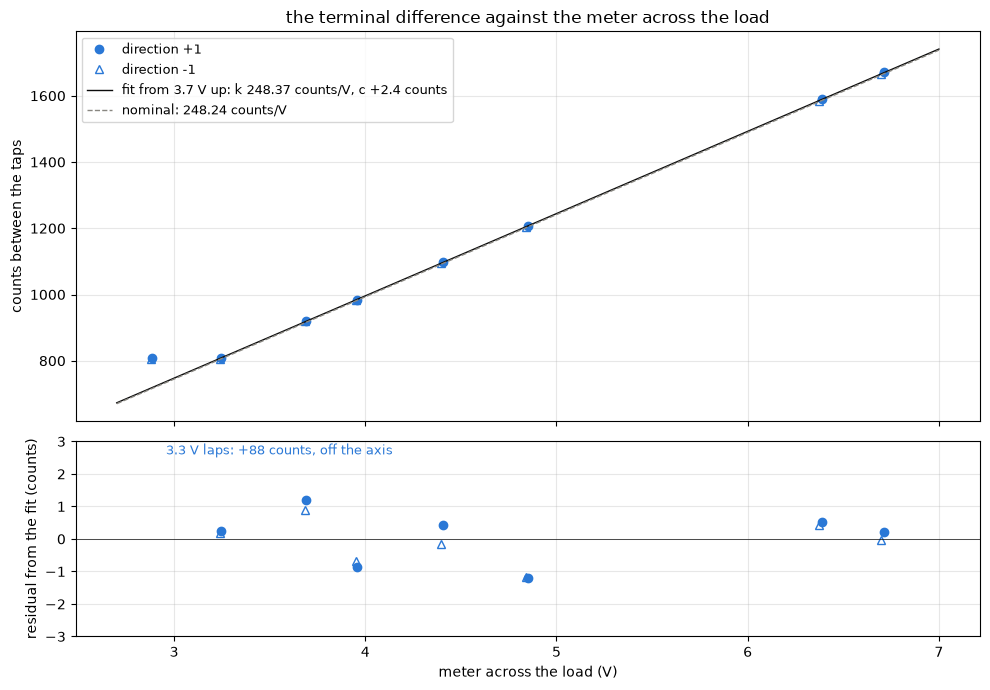

3.7 V up: k 248.37 +/- 0.17 counts/V, c +2.4 +/- 0.8 counts, rms 0.71 counts over 14 points; nominal 248.24, the fit +0.05 % over it
per direction: k 248.37 and 248.36 counts/V, c +2.4 and +2.3
at the nominal conversion the chip reads +0.15 to +0.44 % of the meter from 3.7 V up, mean +0.27 %; at 3.3 V +12.6 %


In [9]:
L_ = T["load"]
L_["counts"] = (L_["vmotor_a"] - L_["vmotor_b"]).abs(); L_["volts"] = L_["meter"].abs()
L_["diff_v"] = np.abs(BOARD.diff_v(L_["vmotor_a"], L_["vmotor_b"]))                   # the chip at the nominal conversion
L_["error_pct"] = (L_["diff_v"] / L_["volts"] - 1) * 100
hi = L_[L_["hi"]]
fit_term = laps.line(hi["volts"], hi["counts"])
fit_term_dir = {dd: laps.line(hi[hi["dir"] == dd]["volts"], hi[hi["dir"] == dd]["counts"]) for dd in (1, -1)}
L_["resid"] = L_["counts"] - (fit_term["slope"] * L_["volts"] + fit_term["intercept"])
K_NOM = 1 / BOARD.v_term_per_count
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.linspace(2.7, 7, 10)
for dd in (1, -1):
    g = L_[L_["dir"] == dd]
    kw = dict(ls="none", marker=MARK[dd], ms=6, color=COLOR["load"], mfc=COLOR["load"] if dd == 1 else "none", label=f"direction {dd:+d}")
    ax[0].plot(g["volts"], g["counts"], **kw); ax[1].plot(g["volts"], g["resid"], **kw)
ax[0].plot(x, fit_term["slope"] * x + fit_term["intercept"], "-", color=INK, lw=1, label=f"fit from 3.7 V up: k {fit_term['slope']:.2f} counts/V, c {fit_term['intercept']:+.1f} counts")
ax[0].plot(x, K_NOM * x, "--", color=MUTED, lw=1, label=f"nominal: {K_NOM:.2f} counts/V")
ax[0].set_ylabel("counts between the taps"); ax[0].legend(fontsize=9); ax[0].set_title("the terminal difference against the meter across the load")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("residual from the fit (counts)"); ax[1].set_xlabel("meter across the load (V)"); ax[1].set_ylim(-3, 3)
g = L_[~L_["hi"]]; ax[1].annotate(f"3.3 V laps: {g['resid'].mean():+.0f} counts, off the axis", (g["volts"].iloc[0], 2.6), xytext=(10, 0), textcoords="offset points", color=COLOR["load"], fontsize=9)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"3.7 V up: k {fit_term['slope']:.2f} +/- {fit_term['slope_se']:.2f} counts/V, c {fit_term['intercept']:+.1f} +/- {fit_term['intercept_se']:.1f} counts, rms {fit_term['rms']:.2f} counts over {fit_term['n']} points; "
      f"nominal {K_NOM:.2f}, the fit {(fit_term['slope'] / K_NOM - 1) * 100:+.2f} % over it")
print(f"per direction: k {fit_term_dir[1]['slope']:.2f} and {fit_term_dir[-1]['slope']:.2f} counts/V, c {fit_term_dir[1]['intercept']:+.1f} and {fit_term_dir[-1]['intercept']:+.1f}")
print(f"at the nominal conversion the chip reads {hi['error_pct'].min():+.2f} to {hi['error_pct'].max():+.2f} % of the meter from 3.7 V up, mean {hi['error_pct'].mean():+.2f} %; "
      f"at 3.3 V {L_[~L_['hi']]['error_pct'].mean():+.1f} %")

From 3.7 V up the counts between the taps follow the meter to 0.7 counts rms, which is 3 mV at the terminals, with a scale of 248.37 +/- 0.17 counts per volt against the nominal 248.24, 0.05 % over it, and an intercept of 2.4 +/- 0.8 counts, three standard errors from zero. The two directions give the same slope to 0.01 % and the same intercept. Read at the nominal conversion through zero the chip is 0.15 to 0.44 % over the meter on those laps, falling as the level rises, which is the intercept talking, 10 mV at the terminals. The two 3.3 V points sit 90 counts over the line, 12.6 % at the nominal conversion, and are reported with the reference below.

### The single terminal and the bias node under drive

Tap A converted with the registry's formula and the bias node from the rest, against the meter from MOT_A to GND. Left, the chip's reading less the meter, in millivolts, on the high-side laps where the meter reads a terminal near the rail and on the low-side laps where it reads the return path's drop. Right, the move of the bias node that each lap implies, against the voltage the high-side terminal sits above the bias node, beside what the registry's 430 over 100 divider predicts as a bare network. The thing to see is whether the excess grows with the level and whether both sides of the lap tell the same story.

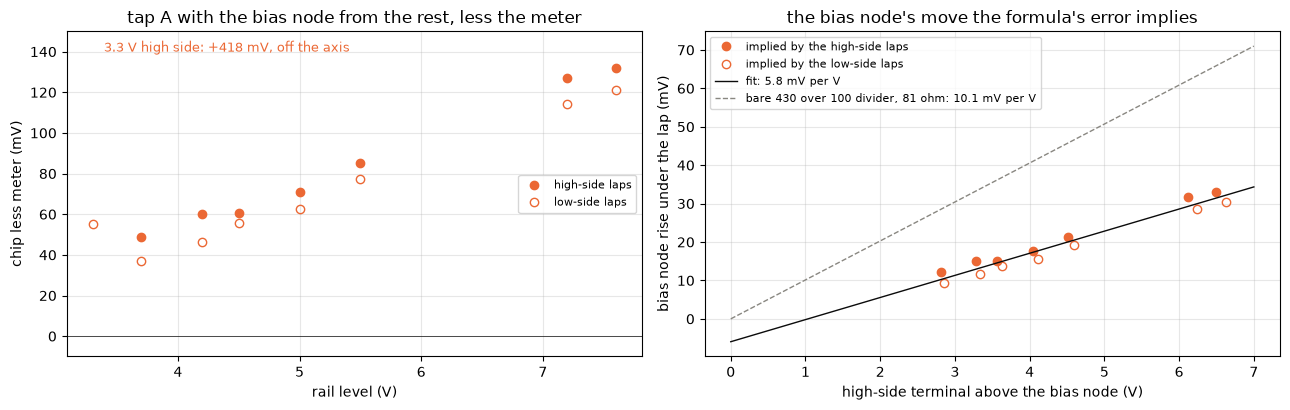

high side, 3.7 V up: chip +1.42 to +1.88 % over the meter, 49 to 132 mV; line through the chip against the meter: slope 1.0236 +/- 0.0009, intercept -35 +/- 5 mV
low side, 3.7 V up: the meter reads 0.191 to 0.414 V of return path, 0.300 to 0.315 ohm at the lap current; the chip reads 37 to 121 mV over it
bias node rise implied: 9 to 33 mV, 5.76 +/- 0.34 mV per volt of leg with an intercept of -5.9 mV; the bare divider predicts 10.1 mV per volt; high and low side agree to 3.4 mV at each level


In [10]:
A = T["tap_a"]
A["term_v"] = BOARD.term_v(A["vmotor_a"], A["vb_rest"])                     # the registry's formula with the bias node from the rest
A["excess_v"] = A["term_v"] - A["meter"]                                     # the chip less the meter
A["side"] = np.where(A["vmotor_a"] > A["vmotor_b"], "high", "low")
A["error_pct"] = A["excess_v"] / A["meter"] * 100
A["vb_rise_mv"] = A["excess_v"] / (BOARD.div_ratio - 1) * 1e3                # the move of the bias node the formula's error implies
A["v_high"] = np.where(A["side"] == "high", A["meter"], BOARD.term_v(A["vmotor_b"], A["vb_rest"]))   # the high-side terminal, the meter on it or tap B's reading
A["leg_v"] = A["v_high"] - A["vb_rest"] * BOARD.v_adc_per_count              # how far the high terminal sits above the bias node
R_TH = BOARD.bias_top * BOARD.bias_bot / (BOARD.bias_top + BOARD.bias_bot)   # the bare divider's source resistance, ohm
R_TAP = BOARD.vmotor_div_top + BOARD.vmotor_div_bot                          # one tap's resistance from the terminal to the bias node
hi = A[A["hi"]]; hs = hi[hi["side"] == "high"]; ls = hi[hi["side"] == "low"]
fit_hs = laps.line(hs["meter"], hs["term_v"])
fit_rise = laps.line(hi["leg_v"], hi["vb_rise_mv"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for side, mfc in (("high", COLOR["tap_a"]), ("low", "none")):
    g = A[A["side"] == side]
    ax[0].plot(g["volts_set"], g["excess_v"] * 1e3, "o", ms=6, color=COLOR["tap_a"], mfc=mfc, label=f"{side}-side laps")
    g = hi[hi["side"] == side]
    ax[1].plot(g["leg_v"], g["vb_rise_mv"], "o", ms=6, color=COLOR["tap_a"], mfc=mfc, label=f"implied by the {side}-side laps")
ax[0].axhline(0, color=INK, lw=0.5); ax[0].set_xlabel("rail level (V)"); ax[0].set_ylabel("chip less meter (mV)"); ax[0].set_title("tap A with the bias node from the rest, less the meter"); ax[0].set_ylim(-10, 150)
g33 = A[(~A["hi"]) & (A["side"] == "high")]; ax[0].annotate(f"3.3 V high side: {g33['excess_v'].iloc[0] * 1e3:+.0f} mV, off the axis", (3.3, 140), xytext=(8, 0), textcoords="offset points", color=COLOR["tap_a"], fontsize=9)
x = np.linspace(0, 7, 5)
ax[1].plot(x, fit_rise["slope"] * x + fit_rise["intercept"], "-", color=INK, lw=1, label=f"fit: {fit_rise['slope']:.1f} mV per V")
ax[1].plot(x, x / R_TAP * R_TH * 1e3, "--", color=MUTED, lw=1, label=f"bare {BOARD.bias_top} over {BOARD.bias_bot} divider, {R_TH:.0f} ohm: {R_TH / R_TAP * 1e3:.1f} mV per V")
ax[1].set_xlabel("high-side terminal above the bias node (V)"); ax[1].set_ylabel("bias node rise under the lap (mV)"); ax[1].set_title("the bias node's move the formula's error implies")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"high side, 3.7 V up: chip {hs['error_pct'].min():+.2f} to {hs['error_pct'].max():+.2f} % over the meter, {hs['excess_v'].min() * 1e3:.0f} to {hs['excess_v'].max() * 1e3:.0f} mV; "
      f"line through the chip against the meter: slope {fit_hs['slope']:.4f} +/- {fit_hs['slope_se']:.4f}, intercept {fit_hs['intercept'] * 1e3:+.0f} +/- {fit_hs['intercept_se'] * 1e3:.0f} mV")
print(f"low side, 3.7 V up: the meter reads {ls['meter'].min():.3f} to {ls['meter'].max():.3f} V of return path, {(ls['meter'] / ls['amps']).min():.3f} to {(ls['meter'] / ls['amps']).max():.3f} ohm at the lap current; "
      f"the chip reads {ls['excess_v'].min() * 1e3:.0f} to {ls['excess_v'].max() * 1e3:.0f} mV over it")
print(f"bias node rise implied: {hi['vb_rise_mv'].min():.0f} to {hi['vb_rise_mv'].max():.0f} mV, {fit_rise['slope']:.2f} +/- {fit_rise['slope_se']:.2f} mV per volt of leg with an intercept of {fit_rise['intercept']:+.1f} mV; "
      f"the bare divider predicts {R_TH / R_TAP * 1e3:.1f} mV per volt; high and low side agree to {np.abs(hs['vb_rise_mv'].to_numpy() - ls['vb_rise_mv'].to_numpy()).max():.1f} mV at each level")

On the high side the chip reads 1.4 to 1.9 % over the meter, 49 to 132 mV, and the excess grows with the level. On the low side the meter reads 0.19 to 0.41 V of return path, 0.30 to 0.31 ohm at the lap current, and the chip reads 37 to 121 mV over that. The two sides agree at every level to 3 mV once each is read as a move of the bias node, which is what one shared node predicts. A line through the high-side chip reading against the meter has a slope of 1.024 and an intercept of -35 mV, the shape a rise proportional to the leg gives. The terminal difference is free of the bias node and reads the meter to 0.05 %, so the ratio $r$ is not what is off here, and the excess is the bias node rising under the lap, by 9 to 33 mV, 5.8 +/- 0.3 mV per volt that the high terminal sits above it, with high confidence.

That slope is a little over half of the 10 mV per volt the registry's 430 over 100 divider gives as a bare network with 81 ohm of source resistance. A bias node with about 45 ohm behind it is the straightforward reading. There is a second reading that the rail pass below raises. If the chip's ground sits above the meter's ground under the lap, every tap reads low by that shift and the bias node's true move is larger than the formula shows, by the same amount on both sides. With the rail pass's 31 to 105 mV taken as a ground shift the implied rise would be 20 to 59 mV, close to the bare divider's prediction. This capture does not separate the two, and a meter on the bias node itself during a lap would.

### The rail at rest and under the lap

The rail tap at the nominal conversion against the meter on VSYS, at rest and under the lap, as a percentage, and the sag the lap pulls on the rail as both instruments see it against the lap current. The thing to see is that the tap agrees with the meter at rest and reads low under the lap, by an amount that grows with the current.

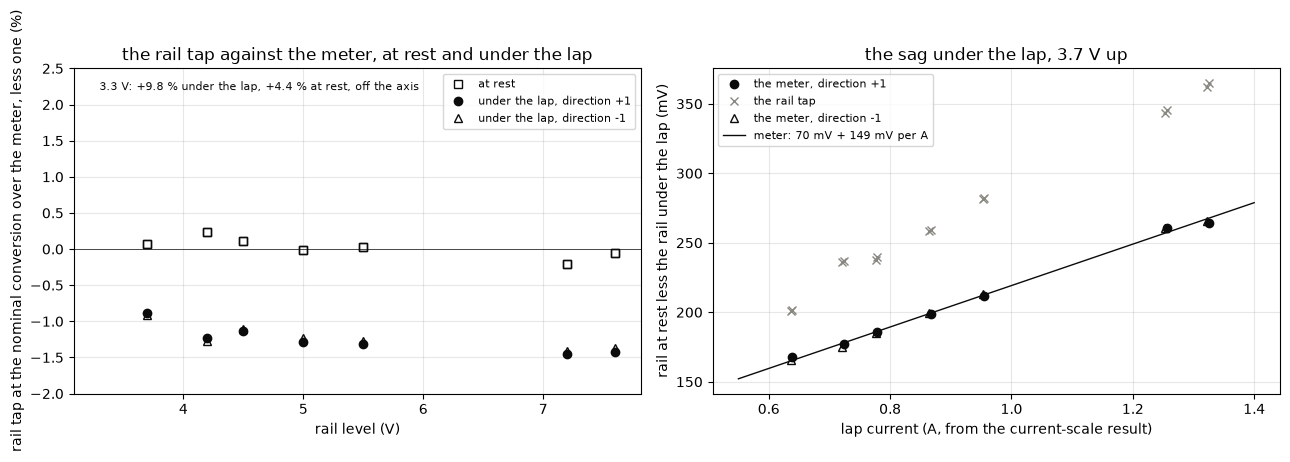

at rest, 3.7 V up: 247.19 +/- 0.23 counts/V, intercept +5.7 +/- 1.3 counts, rms 1.13; the tap reads -0.21 to +0.24 % of the meter
under the lap, 3.7 V up: 243.78 +/- 0.17 counts/V, intercept +6.8 +/- 0.9 counts, rms 0.81; the tap reads -1.45 to -0.88 % of the meter, 31 to 105 mV under it, 49 to 80 mOhm at the lap current
sag by the meter 166 to 266 mV over 0.64 to 1.33 A, 70 +/- 2 mV + 149 +/- 2 mV per A, rms 2.0 mV; the tap sees 201 to 365 mV


inside a lap the rail tap drifts -0.0 to +3.0 counts from its first tenth to its last


In [11]:
Rl = T["rail"]
Rl["rail_v"] = BOARD.rail_v(Rl["vbus_raw"]); Rl["rail_rest_v"] = BOARD.rail_v(Rl["rail_rest"])
Rl["error_pct"] = (Rl["rail_v"] / Rl["meter"] - 1) * 100; Rl["error_rest_pct"] = (Rl["rail_rest_v"] / Rl["meter_rest"] - 1) * 100
Rl["sag_meter"] = Rl["meter_rest"] - Rl["meter"]; Rl["sag_chip"] = Rl["rail_rest_v"] - Rl["rail_v"]
Rl["deficit_v"] = Rl["meter"] - Rl["rail_v"]                                 # what the tap reads under the meter under the lap
hi = Rl[Rl["hi"]]
fit_rail_rest = laps.line(hi["meter_rest"], hi["rail_rest"]); fit_rail_lap = laps.line(hi["meter"], hi["vbus_raw"])
fit_sag = laps.line(hi["amps"], hi["sag_meter"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(Rl["volts_set"], Rl["error_rest_pct"], "s", ms=6, color=COLOR["rail"], mfc="none", label="at rest")
for dd in (1, -1):
    g = Rl[Rl["dir"] == dd]
    ax[0].plot(g["volts_set"], g["error_pct"], MARK[dd], ms=6, color=COLOR["rail"], mfc=COLOR["rail"] if dd == 1 else "none", label=f"under the lap, direction {dd:+d}")
    g = hi[hi["dir"] == dd]
    ax[1].plot(g["amps"], g["sag_meter"] * 1e3, MARK[dd], ms=6, color=COLOR["rail"], mfc=COLOR["rail"] if dd == 1 else "none", label=f"the meter, direction {dd:+d}")
    ax[1].plot(g["amps"], g["sag_chip"] * 1e3, "x", ms=6, color=MUTED, label="the rail tap" if dd == 1 else None)
ax[0].axhline(0, color=INK, lw=0.5); ax[0].set_xlabel("rail level (V)"); ax[0].set_ylabel("rail tap at the nominal conversion over the meter, less one (%)")
ax[0].set_title("the rail tap against the meter, at rest and under the lap"); ax[0].set_ylim(-2, 2.5)
ax[0].annotate(f"3.3 V: {Rl[~Rl['hi']]['error_pct'].mean():+.1f} % under the lap, {Rl[~Rl['hi']]['error_rest_pct'].mean():+.1f} % at rest, off the axis", (3.3, 2.2), fontsize=8, color=COLOR["rail"])
x = np.linspace(0.55, 1.4, 5)
ax[1].plot(x, (fit_sag["slope"] * x + fit_sag["intercept"]) * 1e3, "-", color=INK, lw=1, label=f"meter: {fit_sag['intercept'] * 1e3:.0f} mV + {fit_sag['slope'] * 1e3:.0f} mV per A")
ax[1].set_xlabel("lap current (A, from the current-scale result)"); ax[1].set_ylabel("rail at rest less the rail under the lap (mV)"); ax[1].set_title("the sag under the lap, 3.7 V up")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"at rest, 3.7 V up: {fit_rail_rest['slope']:.2f} +/- {fit_rail_rest['slope_se']:.2f} counts/V, intercept {fit_rail_rest['intercept']:+.1f} +/- {fit_rail_rest['intercept_se']:.1f} counts, rms {fit_rail_rest['rms']:.2f}; "
      f"the tap reads {hi['error_rest_pct'].min():+.2f} to {hi['error_rest_pct'].max():+.2f} % of the meter")
print(f"under the lap, 3.7 V up: {fit_rail_lap['slope']:.2f} +/- {fit_rail_lap['slope_se']:.2f} counts/V, intercept {fit_rail_lap['intercept']:+.1f} +/- {fit_rail_lap['intercept_se']:.1f} counts, rms {fit_rail_lap['rms']:.2f}; "
      f"the tap reads {hi['error_pct'].min():+.2f} to {hi['error_pct'].max():+.2f} % of the meter, {hi['deficit_v'].min() * 1e3:.0f} to {hi['deficit_v'].max() * 1e3:.0f} mV under it, "
      f"{(hi['deficit_v'] / hi['amps']).min() * 1e3:.0f} to {(hi['deficit_v'] / hi['amps']).max() * 1e3:.0f} mOhm at the lap current")
print(f"sag by the meter {hi['sag_meter'].min() * 1e3:.0f} to {hi['sag_meter'].max() * 1e3:.0f} mV over {hi['amps'].min():.2f} to {hi['amps'].max():.2f} A, "
      f"{fit_sag['intercept'] * 1e3:.0f} +/- {fit_sag['intercept_se'] * 1e3:.0f} mV + {fit_sag['slope'] * 1e3:.0f} +/- {fit_sag['slope_se'] * 1e3:.0f} mV per A, rms {fit_sag['rms'] * 1e3:.1f} mV; "
      f"the tap sees {hi['sag_chip'].min() * 1e3:.0f} to {hi['sag_chip'].max() * 1e3:.0f} mV")
drift = []
for _, L in levels["rail"].iterrows():
    d_, m_ = tel.load(CAPTURE / "rail" / L["folder"])
    for seg, g in d_[d_["seg"] > 0].groupby("seg"):
        s = tel.settled(g); q = len(s) // 10
        drift.append(s["vbus_raw"].iloc[-q:].mean() - s["vbus_raw"].iloc[:q].mean())     # last tenth less first tenth of the lap
print(f"inside a lap the rail tap drifts {min(drift):+.1f} to {max(drift):+.1f} counts from its first tenth to its last")

At rest the rail tap reads the meter to within 0.25 % at every level from 3.7 V up, 247.2 +/- 0.2 counts per volt with an intercept of 5.7 +/- 1.3 counts, and the fine pass below pins this better. Under the lap the same tap reads 0.9 to 1.45 % under the meter, 31 to 105 mV, and the deficit grows with the lap current, 49 mOhm at 0.64 A to 80 mOhm at 1.33 A, so it is not a fixed resistance. The tap drifts up to 3 counts over a lap, 12 mV, and the meter's window is the middle of it, so the window is not it. The meter's sag under the lap is 166 to 266 mV, a fixed 70 mV plus 149 mV per amp, which is the dev board's feed diode and the DPS leads, and the tap sees 35 to 100 mV more sag than the meter does.

Two things could make the tap read low under current and not at rest. A drop between the meter's probe points and the tap's own nodes, copper or a connector on the VSYS side or on the ground side, would do it, and a shift of the chip's ground above the meter's GND clip would show on every tap the same way, which is the second reading of the bias node above. The deficit grows faster than the current, which neither a fixed copper path nor the shunt's 60 mOhm gives on its own. VDD rising under the lap is excluded by the terminal difference, which would read low by the same share and reads 0.3 % high instead. The meter at the tap's own pads under a lap, or at the chip's ground pin against the GND clip, separates the two. For a later stage the rail under drive is the practical quantity, and the result file carries both scales.

### The rail on the fine grid

The rail tap's code against the meter over 216 points from 3.7 to 8.0 V, with one line through all of them, and the residual from that line against the meter. The thing to see is how straight the line is at this resolution and that the residual has structure of its own.

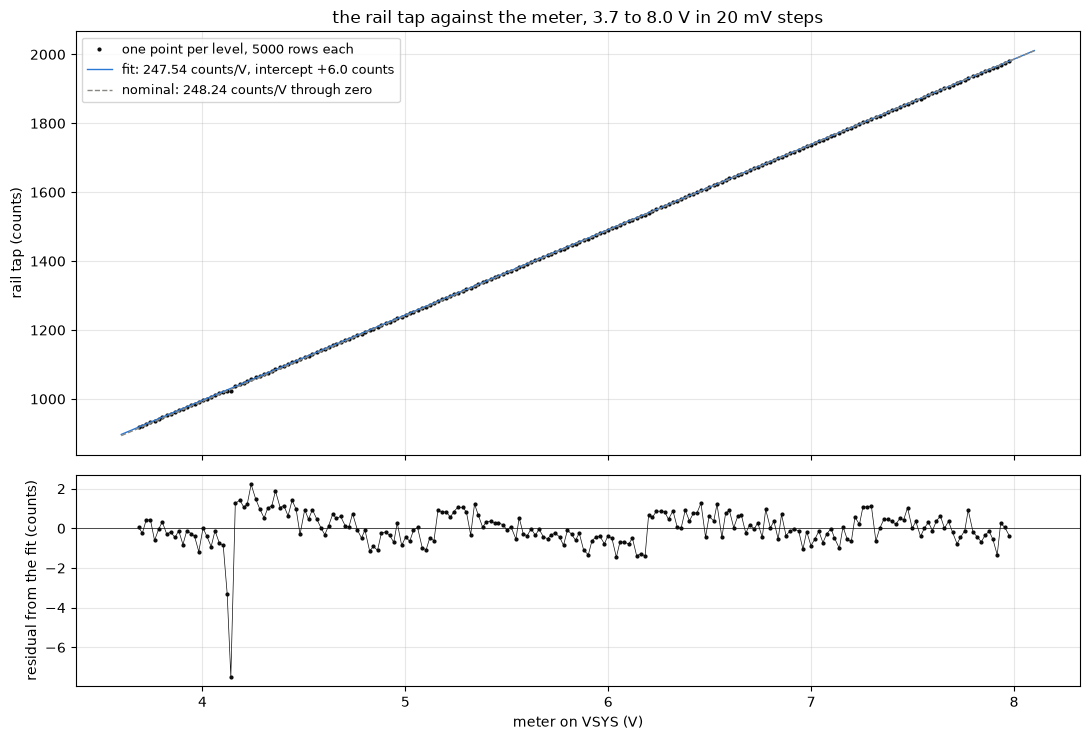

216 points, 6 to 8 packets each, codes 918 to 1980
fit: 247.54 +/- 0.05 counts/V, intercept +5.95 +/- 0.29 counts, residual 0.89 counts rms, -7.5 to +2.2; nominal 248.24, the fit -0.28 % under it
with the packets' mean in place of the median: 247.49 counts/V, intercept +7.12, rms 0.88
per point: tap sd 0.05 to 2.40 counts, meter spread 9 to 29 mV, second half of the stream less the first 1.5 counts at most


In [12]:
rows = []
dF = dmm["rail-fine"]
for _, L in levels["rail-fine"].iterrows():
    d_, m_ = tel.load(CAPTURE / "rail-fine" / L["folder"], BOARD); b = d_[d_["seg"] == 0]
    m = dF[(dF["t_host"] - LAG >= L["t_set"] + 0.6) & (dF["t_host"] - LAG <= L["t_end"])]["value"]   # the point's packets, lag taken out
    rows.append({"k": int(L["k"]), "volts_set": L["volts_set"], "code": b["vbus_raw"].mean(), "code_sd": b["vbus_raw"].std(), "rows": len(b),
                 "vref": b["vref_raw"].mean(), "ntc": b["ntc_raw"].mean(), "meter": float(m.median()), "meter_mean": float(m.mean()), "meter_n": len(m),
                 "meter_pp": float(m.max() - m.min()), "drift": b["vbus_raw"].iloc[len(b) // 2:].mean() - b["vbus_raw"].iloc[:len(b) // 2].mean()})
F = pd.DataFrame(rows)
fit_fine = laps.line(F["meter"], F["code"])
F["resid"] = F["code"] - (fit_fine["slope"] * F["meter"] + fit_fine["intercept"])
fit_fine_mean = laps.line(F["meter_mean"], F["code"])                                    # the same with the packets' mean, for the limitations
K_RAIL = 1 / BOARD.v_rail_per_count
fig, ax = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(F["meter"], F["code"], ".", ms=4, color=COLOR["rail-fine"], label="one point per level, 5000 rows each")
x = np.linspace(3.6, 8.1, 5)
ax[0].plot(x, fit_fine["slope"] * x + fit_fine["intercept"], "-", color=BLUE, lw=1, label=f"fit: {fit_fine['slope']:.2f} counts/V, intercept {fit_fine['intercept']:+.1f} counts")
ax[0].plot(x, K_RAIL * x, "--", color=MUTED, lw=1, label=f"nominal: {K_RAIL:.2f} counts/V through zero")
ax[0].set_ylabel("rail tap (counts)"); ax[0].legend(fontsize=9); ax[0].set_title("the rail tap against the meter, 3.7 to 8.0 V in 20 mV steps")
ax[1].plot(F["meter"], F["resid"], ".-", ms=4, lw=0.5, color=COLOR["rail-fine"]); ax[1].axhline(0, color=INK, lw=0.5)
ax[1].set_ylabel("residual from the fit (counts)"); ax[1].set_xlabel("meter on VSYS (V)")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"{len(F)} points, {F['meter_n'].min()} to {F['meter_n'].max()} packets each, codes {F['code'].min():.0f} to {F['code'].max():.0f}")
print(f"fit: {fit_fine['slope']:.2f} +/- {fit_fine['slope_se']:.2f} counts/V, intercept {fit_fine['intercept']:+.2f} +/- {fit_fine['intercept_se']:.2f} counts, residual {fit_fine['rms']:.2f} counts rms, "
      f"{F['resid'].min():+.1f} to {F['resid'].max():+.1f}; nominal {K_RAIL:.2f}, the fit {(fit_fine['slope'] / K_RAIL - 1) * 100:+.2f} % under it")
print(f"with the packets' mean in place of the median: {fit_fine_mean['slope']:.2f} counts/V, intercept {fit_fine_mean['intercept']:+.2f}, rms {fit_fine_mean['rms']:.2f}")
print(f"per point: tap sd {F['code_sd'].min():.2f} to {F['code_sd'].max():.2f} counts, meter spread {F['meter_pp'].min() * 1e3:.0f} to {F['meter_pp'].max() * 1e3:.0f} mV, "
      f"second half of the stream less the first {F['drift'].abs().max():.1f} counts at most")

One line fits 216 points over 4.3 V to 0.89 counts rms, 247.54 +/- 0.05 counts per volt and an intercept of 5.9 +/- 0.3 counts, 0.3 % under the nominal scale. The residual is not noise around that line. It has a sawtooth in it, and one point near 4.15 V sits 7.5 counts under the line while its neighbors sit near it.

### The residual against the code

The same residual against the code the converter produced, with every multiple of 256 marked, the residual folded onto its position inside a 256 block, and a close look at the codes around 1024 with the count of rows the whole pass read at each code. The thing to see is that the pattern repeats with the code and not with the voltage.

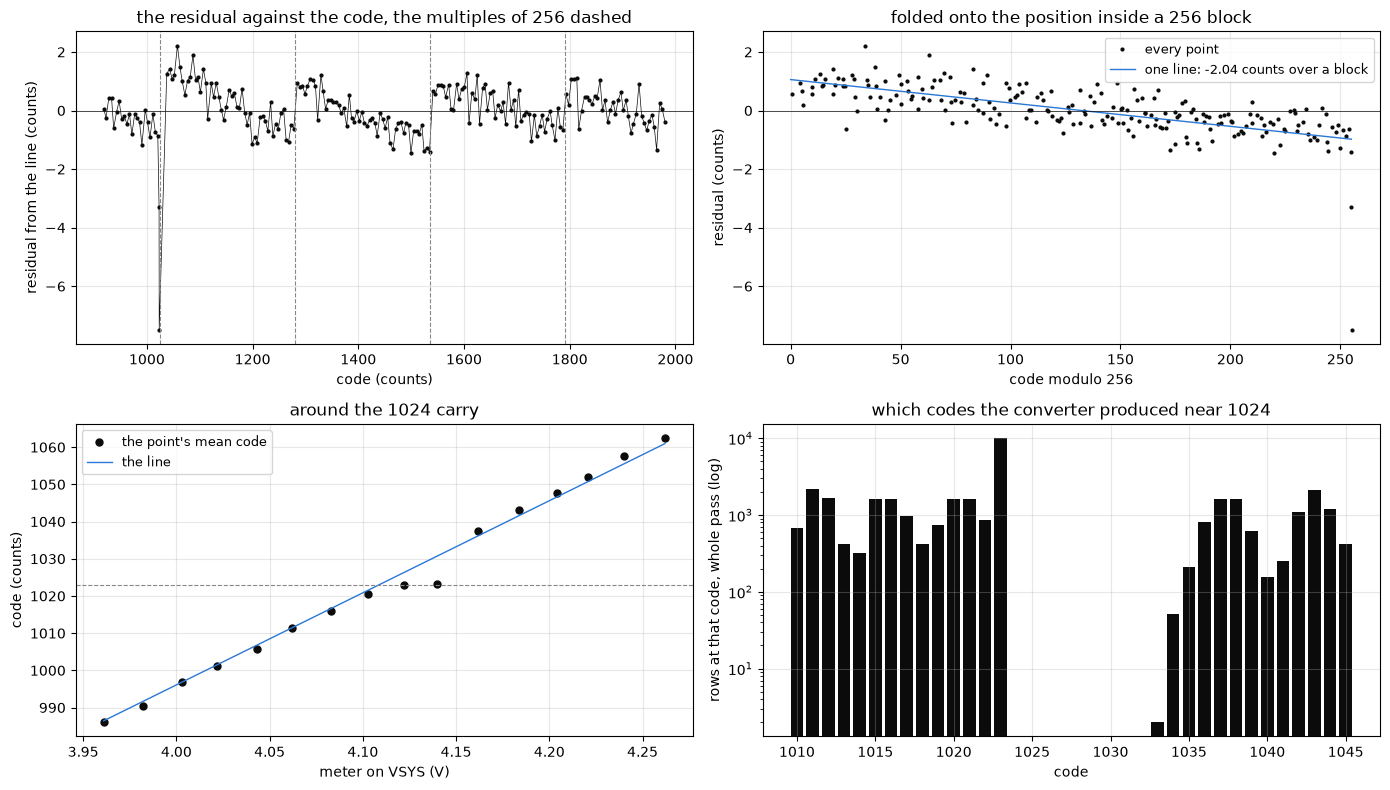

per block, the two 1023 points left out: 768 to 1023: 20 points, -1.81 counts over the block, residual -1.2 to +0.4; 1024 to 1279: 50 points, -2.53 counts over the block, residual -1.1 to +2.2; 1280 to 1535: 52 points, -2.07 counts over the block, residual -1.5 to +1.2; 1536 to 1791: 51 points, -1.46 counts over the block, residual -1.0 to +1.3; 1792 to 2047: 39 points, -1.46 counts over the block, residual -1.3 to +1.1
one sawtooth through every block: -2.04 +/- 0.16 counts over 256 codes; residual after it 0.67 counts rms, 0.48 without the two points at 1023
codes never produced in 1080000 rows between 918 and 1980: [1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032, 1280, 1281]; rows at 1023: 10054, the median code has 1027
rows at the other carries: {1279: 2217, 1280: 0, 1281: 0, 1282: 16, 1535: 547, 1536: 5, 1537: 233, 1791: 1180, 1792: 2, 1793: 244}
the two points that read 1023: means [1023.0, 1023.27], sd [0.05, 1.74], the line puts them at [1026.3, 1030.8], residuals [-3.3,

In [13]:
F["block"] = (F["code"] // 256).astype(int); F["phase"] = F["code"] % 256
fit_saw = laps.line(F["phase"], F["resid"])                                              # one sawtooth through every block
F["after_saw"] = F["resid"] - (fit_saw["slope"] * F["phase"] + fit_saw["intercept"])
clear = (F["code"] < 1015) | (F["code"] > 1030)                                           # every point but the two stuck at 1023
per_block = F[clear].groupby("block").apply(lambda g: pd.Series({"n": len(g), "slope": laps.line(g["phase"], g["resid"])["slope"], "lo": g["resid"].min(), "hi": g["resid"].max()}), include_groups=False)
rest_rows = lambda f: (lambda d: d[d["seg"] == 0]["vbus_raw"])(pd.read_csv(CAPTURE / "rail-fine" / f / "sweep.csv"))
hist = pd.concat([rest_rows(f) for f in levels["rail-fine"]["folder"]]).value_counts().sort_index()   # rows per code over every rest of the pass
never = [c for c in range(int(F["code"].min()), int(F["code"].max())) if hist.get(c, 0) == 0]
never_1024 = [c for c in never if 1024 <= c < 1280]
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(F["code"], F["resid"], ".-", ms=4, lw=0.5, color=COLOR["rail-fine"])
for c in range(1024, 2048, 256):
    ax[0, 0].axvline(c, color=MUTED, lw=0.8, ls="--")
ax[0, 0].axhline(0, color=INK, lw=0.5); ax[0, 0].set_xlabel("code (counts)"); ax[0, 0].set_ylabel("residual from the line (counts)"); ax[0, 0].set_title("the residual against the code, the multiples of 256 dashed")
ax[0, 1].plot(F["phase"], F["resid"], ".", ms=4, color=COLOR["rail-fine"], label="every point")
x = np.array([0, 255]); ax[0, 1].plot(x, fit_saw["slope"] * x + fit_saw["intercept"], "-", color=BLUE, lw=1, label=f"one line: {fit_saw['slope'] * 256:+.2f} counts over a block")
ax[0, 1].axhline(0, color=INK, lw=0.5); ax[0, 1].set_xlabel("code modulo 256"); ax[0, 1].set_ylabel("residual (counts)"); ax[0, 1].set_title("folded onto the position inside a 256 block"); ax[0, 1].legend(fontsize=9)
z = F[(F["code"] > 985) & (F["code"] < 1065)]
ax[1, 0].plot(z["meter"], z["code"], "o", ms=5, color=COLOR["rail-fine"], label="the point's mean code")
ax[1, 0].plot(z["meter"], fit_fine["slope"] * z["meter"] + fit_fine["intercept"], "-", color=BLUE, lw=1, label="the line")
ax[1, 0].axhline(1023, color=MUTED, lw=0.8, ls="--"); ax[1, 0].set_xlabel("meter on VSYS (V)"); ax[1, 0].set_ylabel("code (counts)"); ax[1, 0].set_title("around the 1024 carry"); ax[1, 0].legend(fontsize=9)
h = hist[(hist.index >= 1010) & (hist.index <= 1045)]
ax[1, 1].bar(h.index, h.values, width=0.8, color=COLOR["rail-fine"]); ax[1, 1].set_yscale("log")
ax[1, 1].set_xlabel("code"); ax[1, 1].set_ylabel("rows at that code, whole pass (log)"); ax[1, 1].set_title("which codes the converter produced near 1024")
for a in ax.ravel():
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("per block, the two 1023 points left out: " + "; ".join(f"{int(b * 256)} to {int(b * 256 + 255)}: {int(r['n'])} points, {r['slope'] * 256:+.2f} counts over the block, residual {r['lo']:+.1f} to {r['hi']:+.1f}" for b, r in per_block.iterrows()))
print(f"one sawtooth through every block: {fit_saw['slope'] * 256:+.2f} +/- {fit_saw['slope_se'] * 256:.2f} counts over 256 codes; residual after it {F['after_saw'].std():.2f} counts rms, "
      f"{F[clear]['after_saw'].std():.2f} without the two points at 1023")
print(f"codes never produced in {int(hist.sum())} rows between {F['code'].min():.0f} and {F['code'].max():.0f}: {never}; rows at 1023: {int(hist[1023])}, the median code has {int(hist[(hist.index > 930) & (hist.index < 1970)].median())}")
at = {c: int(hist.get(c, 0)) for c in (1279, 1280, 1281, 1282, 1535, 1536, 1537, 1791, 1792, 1793)}
print("rows at the other carries:", at)
w23 = z[z["code"].round(0) == 1023]
print(f"the two points that read 1023: means {w23['code'].round(2).tolist()}, sd {w23['code_sd'].round(2).tolist()}, the line puts them at {(fit_fine['slope'] * w23['meter'] + fit_fine['intercept']).round(1).tolist()}, "
      f"residuals {w23['resid'].round(1).tolist()}; with {len(never_1024)} codes missing above it, code 1023 spans about {len(never_1024) + 1} codes of input")
INL = F.sort_values("code")[["code", "resid"]].rename(columns={"resid": "residual_counts"})
INL_PATH = Path("results") / f"{BOARD.key}-inl.csv"; INL_PATH.parent.mkdir(exist_ok=True)
INL.to_csv(INL_PATH, index=False, float_format="%.3f")
print(f"wrote {INL_PATH}: {len(INL)} rows, code and residual_counts, sorted by code")

The residual follows the code. Inside each 256 block it falls by about 2 counts from the block's start to its end and jumps back up at the next multiple of 256, at 1280, 1536 and 1792 alike, and one sawtooth through every block takes the residual from 0.89 to 0.67 counts rms, 0.48 without the two points at 1023. The size of the tooth shrinks as the code rises, 2.5 counts in the 1024 block and 1.5 in the 1792 block. At every one of those multiples the code just above the carry is nearly or wholly absent, 1280 and 1281 never, 1536 five rows and 1792 two rows out of about 1000 at a typical code.

The 1024 carry is the largest. Codes 1024 to 1032 never appear in the 1.08 million rest rows of the pass, 1023 appears ten times as often as any other code, and the two points that read it are stuck there, one at 1023.0 with 0.05 counts of spread over 5000 rows and the next at 1023.3 where the line puts the input at 1031. The converter holds 1023 over about ten codes of input and then skips to 1033. The width and the missing codes cancel in the integral, so above 1033 the residual is continuous with the block below, and the map carries the two 1023 points as they are.

The alternatives, and what this data says about each.

| Candidate | What the data says | Confidence |
|---|---|---|
| The converter's own linearity, a weight error at the 256 carry and a wide code at 1023 | The pattern repeats with the code, at 1280, 1536 and 1792, and not with the voltage. The codes just above each carry are missing in the raw rows, which no source outside the converter can make. | Likely. This is what the map carries. |
| DPS ripple or settling inside a point | The tap's spread inside a point is 0.9 to 2.4 counts, the rest-noise floor, and the stream's second half differs from its first by 1.5 counts at most. Neither correlates with the residual. | Excluded as the sawtooth. It is in the scatter about it. |
| The meter's own steps and linearity | The meter moves in 1 mV steps, 0.25 counts, and reads the DPS set point to a millivolt in a straight line over the pass. A sawtooth of 2 counts with a period of 256 codes would need the meter to know the converter's code. | Excluded. |
| The time join, packets from the previous level inside the window | Taking the packets' mean in place of the median moves the intercept by 1.2 counts and the slope by 0.02 % and leaves the residual at 0.88 rms, with the same sawtooth. A tighter window around the stream does the same with fewer packets. | Excluded as the sawtooth. It bounds the intercept. |
| The rail's rest-noise pattern | The floor is a frame-locked pattern of 1 to 1.5 counts that a 5000 row mean averages to a few hundredths. | Excluded. |
| The reference moving with the level | The 1.2 V reference reads VDD rising 11 mV from 3.7 to 8 V, which would be a smooth bow of 0.9 counts, not a sawtooth, and the residual has no bow of that size. Checked below. | Excluded as the sawtooth. |

A finer ripple of about half a count with a period of some tens of codes is also visible in the residual. The grid steps 4.9 codes per point, which does not resolve it, and it is left as observed.

### The ADC's share of the current-scale series step

The current-scale notebook left a step of 4.7 counts between its 4.5 V and 5.0 V series laps, raw codes 1526 to 1564 across the 1536 carry, and a second series pass repeats it at 4.4 counts. Here the map is subtracted from each series lap's code and from its zero by interpolation, and the step from the common line through both loads is read before and after, for both series passes.

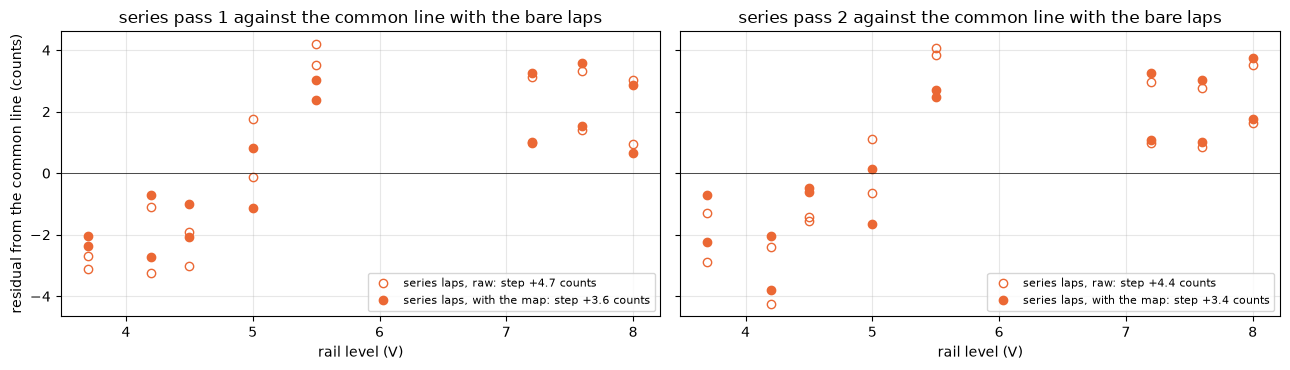

series pass 1: step +4.73 -> +3.61 counts, series rms about the common line 2.60 -> 2.17, all laps 2.19 -> 1.94, G 1135.0 -> 1134.5
series pass 2: step +4.41 -> +3.40 counts, series rms about the common line 2.55 -> 2.23, all laps 2.16 -> 1.99, G 1134.8 -> 1134.3
the map takes 1.0 to 1.1 counts out of the step; the bare laps sit above code 1930, outside the map, and are left as they are


In [14]:
CS_ROOT = CAPTURE.parent.parent / "current-scale"
inl = INL.to_numpy()
def inl_corrected(code):
    # the code less the map residual at it, by interpolation; codes outside the map are left alone
    code = np.asarray(code, float); inside = (code >= inl[0, 0]) & (code <= inl[-1, 0])
    return np.where(inside, code - np.interp(code, inl[:, 0], inl[:, 1]), code)

steps = []
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, capn in zip(ax, (1, 2)):
    parts = []
    for p, cap in (("bare", 1), ("series", capn)):
        folder = CS_ROOT / f"capture-{cap}" / p
        t = laps.table(folder, BOARD, b41t.load(folder / "dmm.csv")); t["amps"] = t["meter"].abs(); t["pass_"] = p
        parts.append(t[t["volts_set"] > 3.4])
    C = pd.concat(parts, ignore_index=True)
    C["counts"] = C["current_raw"] - C["zero"]; C["counts_c"] = inl_corrected(C["current_raw"]) - inl_corrected(C["zero"])
    for col, name, mfc in (("counts", "raw", "none"), ("counts_c", "with the map", ORANGE)):
        fx = laps.line(C["amps"], C[col]); C["r"] = C[col] - (fx["slope"] * C["amps"] + fx["intercept"])       # the common line through both loads
        s = C[C["pass_"] == "series"]; lo_, hi_ = s[s["volts_set"] <= 4.5]["r"], s[s["volts_set"] >= 5.0]["r"]
        steps.append({"capture": capn, "which": name, "step": hi_.mean() - lo_.mean(), "series_rms": np.sqrt((s["r"] ** 2).mean()), "all_rms": fx["rms"], "G": fx["slope"]})
        a.plot(s["volts_set"], s["r"], "o", ms=6, color=ORANGE, mfc=mfc, label=f"series laps, {name}: step {hi_.mean() - lo_.mean():+.1f} counts")
    a.axhline(0, color=INK, lw=0.5); a.set_xlabel("rail level (V)"); a.set_title(f"series pass {capn} against the common line with the bare laps"); a.legend(fontsize=8); a.grid(alpha=0.3)
ax[0].set_ylabel("residual from the common line (counts)")
plt.tight_layout(); plt.show()
steps = pd.DataFrame(steps)
for capn in (1, 2):
    r, c = steps[(steps["capture"] == capn) & (steps["which"] == "raw")].iloc[0], steps[(steps["capture"] == capn) & (steps["which"] != "raw")].iloc[0]
    print(f"series pass {capn}: step {r['step']:+.2f} -> {c['step']:+.2f} counts, series rms about the common line {r['series_rms']:.2f} -> {c['series_rms']:.2f}, "
          f"all laps {r['all_rms']:.2f} -> {c['all_rms']:.2f}, G {r['G']:.1f} -> {c['G']:.1f}")
STEP_RAW = steps[steps["which"] == "raw"]["step"].to_numpy(); STEP_C = steps[steps["which"] != "raw"]["step"].to_numpy()
print(f"the map takes {(STEP_RAW - STEP_C).min():.1f} to {(STEP_RAW - STEP_C).max():.1f} counts out of the step; the bare laps sit above code 1930, outside the map, and are left as they are")

The map takes a count out of the step in both passes, 4.7 to 3.6 and 4.4 to 3.4, and the series residuals about the common line fall from 2.6 to 2.2 counts rms. The converter accounts for about a count of the step and the remaining 3.4 to 3.6 counts stay open to current-scale, where the candidates are listed.

### The reference and the bias node

Left, VDD from the chip's 1.2 V reference against the level, from the `vdd` pass and from the fine pass's reference rows. Middle, the rail tap at rest against the meter, read at the nominal 3.3 V and read ratiometrically with the measured VDD, as a percentage, over the fine pass. Right, the bias node at rest against the level, in counts from the chip's two taps in every pass and in volts from the meter in the `tap_a` rests. The thing to see is where VDD drops out, whether the ratiometric reading is better, and whether the bias node moves with the level at all.

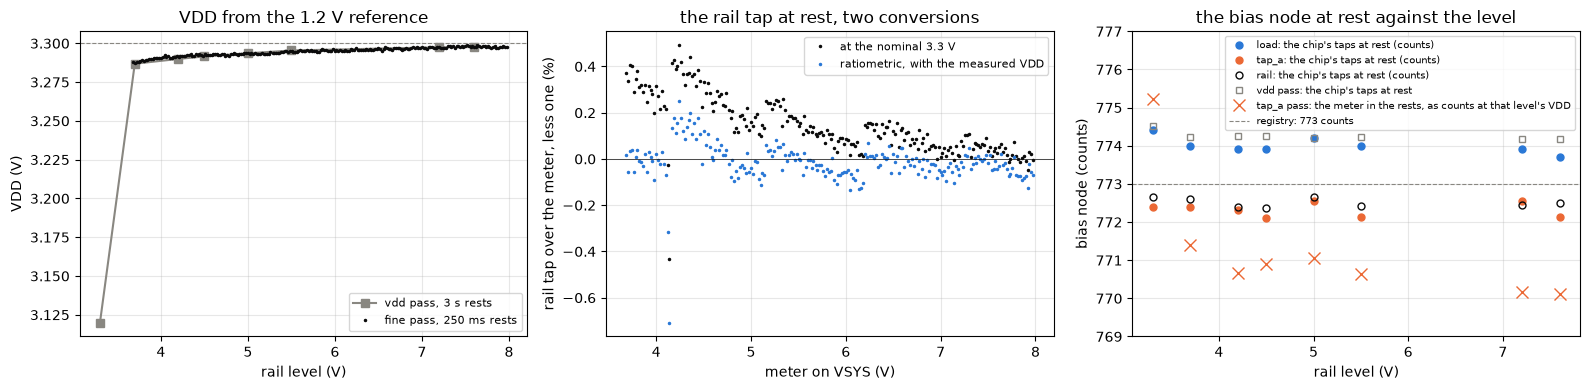

VDD: 3.287 to 3.298 V from 3.7 V up, rising 2.5 +/- 0.4 mV per volt of rail; 3.120 V at the 3.3 V level, -5.3 %; the fine pass reads 3.287 to 3.299 V
the rail tap at rest, fine pass: at the nominal 3.3 V 247.54 counts/V, rms 0.89; ratiometric 247.98 +/- 0.05 counts/V, intercept +1.3, rms 0.94; the divider alone is then -0.11 % off its nominal ratio
a VDD rising 2.5 mV per volt would bend the raw residual by -0.19 counts per V^2, 0.87 counts of bow across the range; the residual's own quadratic term is +0.03 +/- 0.03 counts per V^2, 0.12 counts of bow
bias node at rest: the chip reads 772.1 to 774.4 counts across the lap passes from 3.3 V up and 774.2 to 774.5 in the vdd pass, against 773 nominal; the meter reads 0.619 to 0.620 V in the rests from 3.7 V up, 770 to 771 counts at the measured VDD, against 0.6226 V nominal; at 3.3 V it reads 0.591 V, 775 counts at that level's VDD of 3.120 V


In [15]:
rows = []
for _, L in levels["vdd"].iterrows():
    d_, m_ = tel.load(CAPTURE / "vdd" / L["folder"], BOARD); b = tel.baseline(d_)
    rows.append({"volts_set": L["volts_set"], "vref": b["vref_raw"].mean(), "vdd_v": float(BOARD.vdd_v(b["vref_raw"].mean())), "vbus": b["vbus_raw"].mean(),
                 "tap_a": b["vmotor_a"].mean(), "tap_b": b["vmotor_b"].mean(), "zero": b["current_raw"].median()})
V = pd.DataFrame(rows)
V["rail_nom"] = BOARD.rail_v(V["vbus"]); V["rail_ratio"] = BOARD.rail_v(V["vbus"], V["vref"])
F["vdd_v"] = BOARD.vdd_v(F["vref"]); F["rail_nom"] = BOARD.rail_v(F["code"]); F["rail_ratio"] = BOARD.rail_v(F["code"], F["vref"])
fit_ratio = laps.line(F["meter"], F["code"] * F["vdd_v"] / (BOARD.vdd_mv / 1e3))         # the code as it would read at exactly 3.3 V
fit_vdd = laps.line(V[V["volts_set"] > 3.4]["volts_set"], V[V["volts_set"] > 3.4]["vdd_v"])  # VDD's slope with the rail
(bend, _, _), cov = np.polyfit(F[clear]["meter"] - F["meter"].mean(), F[clear]["resid"], 2, cov=True)   # a bend in the raw residual, counts per V^2
bend_se = np.sqrt(cov[0, 0]); span = F["meter"].max() - F["meter"].min()
bend_pred = -fit_vdd["slope"] / F["vdd_v"].mean() * fit_fine["slope"]                     # code = k V / VDD(V), VDD rising with V, to first order
B_rest = pd.DataFrame([{"pass_": p, "volts_set": L["volts_set"], "chip": pd.concat([b["vmotor_a"], b["vmotor_b"]]).mean()}
                       for p in LAP_PASSES for _, L in levels[p].iterrows() for b in [tel.baseline(tel.load(CAPTURE / p / L["folder"])[0])]])   # both taps over the rest, the same statistic in every pass
meter_vb = T["tap_a"].drop_duplicates("k")[["volts_set", "meter_rest"]].merge(V[["volts_set", "vdd_v"]], on="volts_set")
meter_vb["counts"] = meter_vb["meter_rest"] / meter_vb["vdd_v"] * BOARD.adc_counts           # the meter's volts as counts at that level's VDD
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(V["volts_set"], V["vdd_v"], "s-", color=COLOR["vdd"], label="vdd pass, 3 s rests")
ax[0].plot(F["meter"], F["vdd_v"], ".", ms=3, color=COLOR["rail-fine"], label="fine pass, 250 ms rests")
ax[0].axhline(BOARD.vdd_mv / 1e3, color=MUTED, lw=0.8, ls="--"); ax[0].set_xlabel("rail level (V)"); ax[0].set_ylabel("VDD (V)"); ax[0].set_title("VDD from the 1.2 V reference"); ax[0].legend(fontsize=8)
ax[1].plot(F["meter"], (F["rail_nom"] / F["meter"] - 1) * 100, ".", ms=3, color=COLOR["rail-fine"], label="at the nominal 3.3 V")
ax[1].plot(F["meter"], (F["rail_ratio"] / F["meter"] - 1) * 100, ".", ms=3, color=BLUE, label="ratiometric, with the measured VDD")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xlabel("meter on VSYS (V)"); ax[1].set_ylabel("rail tap over the meter, less one (%)"); ax[1].set_title("the rail tap at rest, two conversions"); ax[1].legend(fontsize=8)
for p in LAP_PASSES:
    g = B_rest[B_rest["pass_"] == p]
    ax[2].plot(g["volts_set"], g["chip"], "o", ms=5, color=COLOR[p], mfc=COLOR[p] if p != "rail" else "none", label=f"{p}: the chip's taps at rest (counts)")
ax[2].plot(V["volts_set"], (V["tap_a"] + V["tap_b"]) / 2, "s", ms=5, color=COLOR["vdd"], mfc="none", label="vdd pass: the chip's taps at rest")
ax[2].plot(meter_vb["volts_set"], meter_vb["counts"], "x", ms=8, color=ORANGE, label="tap_a pass: the meter in the rests, as counts at that level's VDD")
ax[2].axhline(BOARD.bias_nom_counts, color=MUTED, lw=0.8, ls="--", label=f"registry: {BOARD.bias_nom_counts} counts")
ax[2].set_xlabel("rail level (V)"); ax[2].set_ylabel("bias node (counts)"); ax[2].set_title("the bias node at rest against the level"); ax[2].set_ylim(769, 777); ax[2].legend(fontsize=7, loc="upper right")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
hv = V[V["volts_set"] > 3.4]
print(f"VDD: {hv['vdd_v'].min():.3f} to {hv['vdd_v'].max():.3f} V from 3.7 V up, rising {fit_vdd['slope'] * 1e3:.1f} +/- {fit_vdd['slope_se'] * 1e3:.1f} mV per volt of rail; {V['vdd_v'].iloc[0]:.3f} V at the 3.3 V level, "
      f"{(V['vdd_v'].iloc[0] / hv['vdd_v'].mean() - 1) * 100:+.1f} %; the fine pass reads {F['vdd_v'].min():.3f} to {F['vdd_v'].max():.3f} V")
print(f"the rail tap at rest, fine pass: at the nominal 3.3 V {fit_fine['slope']:.2f} counts/V, rms {fit_fine['rms']:.2f}; ratiometric {fit_ratio['slope']:.2f} +/- {fit_ratio['slope_se']:.2f} counts/V, intercept {fit_ratio['intercept']:+.1f}, rms {fit_ratio['rms']:.2f}; "
      f"the divider alone is then {(fit_ratio['slope'] / K_RAIL - 1) * 100:+.2f} % off its nominal ratio")
print(f"a VDD rising {fit_vdd['slope'] * 1e3:.1f} mV per volt would bend the raw residual by {bend_pred:+.2f} counts per V^2, {abs(bend_pred) * span ** 2 / 4:.2f} counts of bow across the range; "
      f"the residual's own quadratic term is {bend:+.2f} +/- {bend_se:.2f} counts per V^2, {abs(bend) * span ** 2 / 4:.2f} counts of bow")
mv = meter_vb[meter_vb["volts_set"] > 3.4]
print(f"bias node at rest: the chip reads {B_rest['chip'].min():.1f} to {B_rest['chip'].max():.1f} counts across the lap passes from 3.3 V up and {((V['tap_a'] + V['tap_b']) / 2).min():.1f} to {((V['tap_a'] + V['tap_b']) / 2).max():.1f} in the vdd pass, "
      f"against {BOARD.bias_nom_counts} nominal; the meter reads {mv['meter_rest'].min():.3f} to {mv['meter_rest'].max():.3f} V in the rests from 3.7 V up, "
      f"{mv['counts'].min():.0f} to {mv['counts'].max():.0f} counts at the measured VDD, against {BOARD.vb_nom_v:.4f} V nominal; at 3.3 V it reads "
      f"{meter_vb[meter_vb['volts_set'] == 3.3]['meter_rest'].iloc[0]:.3f} V, {meter_vb[meter_vb['volts_set'] == 3.3]['counts'].iloc[0]:.0f} counts at that level's VDD of {V['vdd_v'].iloc[0]:.3f} V")

VDD is 3.287 to 3.298 V from 3.7 V up, rising 2.5 +/- 0.4 mV per volt of rail, and 3.120 V at the 3.3 V level, 5.3 % low, the regulator out of headroom on a 1S rail, as the rest-noise and current-scale notebooks found. The fine pass reads the same 11 mV rise over its range in 250 ms rests.

Read ratiometrically the rail tap's scale moves from 247.54 to 247.98 counts per volt, 0.11 % under the divider's nominal ratio, so the 0.3 % at the nominal conversion is two parts, the divider at 0.1 % and VDD at 0.2 % under 3.3 V, and the intercept falls from 5.9 to 1.3 counts, which is why the ratiometric reading sits flat against the level in the middle panel while the nominal one slopes. The ratiometric line fits no better though, 0.94 counts rms against 0.89, and the raw residual does not carry the bow that an 11 mV rise in VDD would put in it. That rise bends the code against the meter by 0.19 counts per volt squared, 0.9 counts of bow across the range, and the residual's own quadratic term is 0.03 +/- 0.03 counts per volt squared, a tenth of it and of the other sign. Either the reference's reading moves with the rail for a reason other than VDD, or VDD does rise and the converter's scale follows it less than ratiometric. A meter on the 3V3 pin over the same grid would say which. Until then the rail tap is best read at the single scale in the result file, and the reference is the right correction for a rail in dropout, where it moves by 5 %, rather than for the 0.3 % above it.

The bias node at rest does not move with the level. The chip's taps read 772 to 775 counts at every level including 3.3 V, against 773 in the registry, steady to a third of a count inside each pass. Between passes they differ by 2 counts, 774 in the `load` and `vdd` passes and 772.3 in `tap_a` and `rail`, which the meter's 1 mV step does not resolve and this capture does not explain. The meter reads 0.619 to 0.620 V in the `tap_a` rests from 3.7 V up, which is 770 to 771 counts at the measured VDD, 3 counts under the chip's own reading and 3 mV under the registry's 0.623 V. At 3.3 V the meter reads 0.591 V, which is the node following VDD into dropout, and in counts at that level's 3.12 V it is 775, so the node is a share of VDD as the registry says. The chip reading three counts over the meter on a node near 0.6 V, and the rail lines having an intercept of 6 counts, point the same way, at a few counts of offset in the converter or the meter at the bottom of its range, and the meter's class on the 20 V range, 0.1 % of the reading plus 2 mV, allows 2.6 mV at this node, 3 counts, so the meter alone could own it.

### The 3.3 V level

Each node at the 3.3 V level, where the reference is in dropout and the lap rows do not carry it.

In [16]:
lo = {p: T[p][~T[p]["hi"]] for p in LAP_PASSES}
vdd_lap = (lo["rail"]["meter"] / BOARD.vbus_ratio * BOARD.adc_counts / lo["rail"]["vbus_raw"]).mean()      # VDD under the lap, if the tap's ratio holds
vdd_rest_rail = (lo["rail"]["meter_rest"] / BOARD.vbus_ratio * BOARD.adc_counts / lo["rail"]["rail_rest"]).mean()
print(f"terminal difference at the nominal conversion: {lo['load']['error_pct'].mean():+.1f} % over the meter; the rest VDD of {V['vdd_v'].iloc[0]:.3f} V accounts for {(3.3 / V['vdd_v'].iloc[0] - 1) * 100:+.1f} %")
print(f"rail tap: {lo['rail']['error_rest_pct'].mean():+.1f} % over the meter at rest, {lo['rail']['error_pct'].mean():+.1f} % under the lap; the meter reads the rail at {lo['rail']['meter_rest'].mean():.3f} V at rest and {lo['rail']['meter'].mean():.3f} V under the lap")
print(f"VDD the rail tap implies with its 3.7 V up scale: {vdd_rest_rail:.3f} V at rest, {vdd_lap:.3f} V under the lap; 3.3 V over that is {(3.3 / vdd_lap - 1) * 100:+.1f} %")
print(f"tap A high side: {lo['tap_a'][lo['tap_a']['side'] == 'high']['error_pct'].mean():+.1f} % over the meter")
print(f"the rail tap under the 3.3 V lap reads {-lo['rail']['sag_chip'].mean() / BOARD.v_rail_per_count:+.1f} counts against its rest while the meter sags {lo['rail']['sag_meter'].mean() * 1e3:.0f} mV")

terminal difference at the nominal conversion: +12.6 % over the meter; the rest VDD of 3.120 V accounts for +5.8 %
rail tap: +4.4 % over the meter at rest, +9.8 % under the lap; the meter reads the rail at 3.314 V at rest and 3.162 V under the lap
VDD the rail tap implies with its 3.7 V up scale: 3.161 V at rest, 3.006 V under the lap; 3.3 V over that is +9.8 %
tap A high side: +13.7 % over the meter
the rail tap under the 3.3 V lap reads +3.0 counts against its rest while the meter sags 152 mV


At the 3.3 V level the terminal difference reads 12.6 % over the meter and the single tap 13.7 %, the rail tap 9.8 % under the lap against 4.4 % at rest. The rail tap even reads 3 counts higher under that lap than at rest while the meter sees 150 mV of sag, which is VDD falling with the rail faster than the rail falls in share. Read through the rail tap's own scale the rest VDD of that pass comes out at 3.16 V at its 3.31 V rail, beside 3.12 V from the reference at the vdd pass's 3.28 V rail, both the regulator in dropout. The rail under the lap is 3.16 V on the meter, 0.15 V below its rest, and the regulator's output follows it down to about 3.0 V by the same route. 3.3 V over that is 10 %, which covers most of the excess on every node with moderate confidence. The rest, a percent or two, is inside what the tap's deficit under the lap and a VDD read through that same tap leave unresolved. Nothing at this level is graded, as in current-scale.

### The results file

The terminal scale and offset from the `load` pass, the single tap's high-side error and the bias node's rise under drive, the rail's scale at rest from the fine pass and from the lap passes, its scale under the lap and the deficit, the sag per amp, the fine pass's residual and the converter's map figures, the series step before and after the map, VDD, the bias node at rest, and the stream offset, each with its standard error or range as the bounds.

In [17]:
q = results.quantity
def se_q(f, key, unit, scale=1):
    return q(f[key] * scale, (f[key] - f[key + "_se"]) * scale, (f[key] + f[key + "_se"]) * scale, unit)
def range_q(s, unit, scale=1):
    return q(s.mean() * scale, s.min() * scale, s.max() * scale, unit)
hiL, hiA, hiR = L_[L_["hi"]], A[A["hi"]], Rl[Rl["hi"]]
results.write("1-board", "terminal-chain", CAPTURE, pair=BOARD.key,
              notes="DC laps at 100 % duty on the bare load with the DMM on DC V at one node per pass, plus a 216 point walk of the rail at rest and a vdd pass; "
                    "scales are counts per volt of the node against the meter, from 3.7 V up; the 3.3 V level is reported apart; the converter's residual on the "
                    "fine grid is in results/<board>-inl.csv as code, residual_counts; the meter's class on the 20 V range is 0.1 % plus 2 mV from the dmm result",
              stream_offset_s=q(OFFSET, edges["offset"].quantile(0.25), edges["offset"].quantile(0.75), "s"),
              terminal_counts_per_v=se_q(fit_term, "slope", "counts/V"),
              terminal_offset_counts=se_q(fit_term, "intercept", "counts"),
              terminal_residual_rms_counts=q(fit_term["rms"], unit="counts"),
              terminal_scale_over_nominal_pct=q((fit_term["slope"] / K_NOM - 1) * 100, unit="%"),
              terminal_error_at_nominal_pct=range_q(hiL["error_pct"], "%"),
              tap_a_high_error_at_nominal_pct=range_q(hiA[hiA["side"] == "high"]["error_pct"], "%"),
              tap_a_low_excess_v=range_q(hiA[hiA["side"] == "low"]["excess_v"], "V"),
              return_path_ohm=range_q(hiA[hiA["side"] == "low"]["meter"] / hiA[hiA["side"] == "low"]["amps"], "ohm"),
              bias_rise_under_drive_mv=range_q(hiA["vb_rise_mv"], "mV"),
              bias_rise_mv_per_v=se_q(fit_rise, "slope", "mV/V"),
              bias_source_ohm_bare_divider=q(R_TH, unit="ohm"),
              rail_counts_per_v=se_q(fit_fine, "slope", "counts/V"),
              rail_offset_counts=se_q(fit_fine, "intercept", "counts"),
              rail_residual_rms_counts=q(fit_fine["rms"], unit="counts"),
              rail_scale_over_nominal_pct=q((fit_fine["slope"] / K_RAIL - 1) * 100, unit="%"),
              rail_counts_per_v_ratiometric=se_q(fit_ratio, "slope", "counts/V"),
              rail_range_v=q(F["meter"].max(), F["meter"].min(), F["meter"].max(), "V"),
              rail_rest_counts_per_v_laps=se_q(fit_rail_rest, "slope", "counts/V"),
              rail_lap_counts_per_v=se_q(fit_rail_lap, "slope", "counts/V"),
              rail_lap_offset_counts=se_q(fit_rail_lap, "intercept", "counts"),
              rail_lap_deficit_v=range_q(hiR["deficit_v"], "V"),
              rail_lap_deficit_ohm=range_q(hiR["deficit_v"] / hiR["amps"], "ohm"),
              rail_sag_v_per_a=se_q(fit_sag, "slope", "V/A"),
              rail_sag_offset_v=se_q(fit_sag, "intercept", "V"),
              rail_sag_v=range_q(hiR["sag_meter"], "V"),
              inl_sawtooth_pp_counts=q(-fit_saw["slope"] * 256, -per_block["slope"].max() * 256, -per_block["slope"].min() * 256, "counts"),
              inl_period_codes=q(256, unit="codes"),
              inl_code_1023_width_codes=q(len(never_1024) + 1, unit="codes"),
              inl_missing_codes_at_1024=q(len(never_1024), unit="codes"),
              inl_code_range=q(F["code"].max(), F["code"].min(), F["code"].max(), "counts"),
              inl_residual_after_sawtooth_rms_counts=q(F["after_saw"].std(), unit="counts"),
              series_step_counts=q(STEP_RAW[0], STEP_RAW.min(), STEP_RAW.max(), "counts"),
              series_step_with_map_counts=q(STEP_C[0], STEP_C.min(), STEP_C.max(), "counts"),
              vdd_v=range_q(hv["vdd_v"], "V"),
              vdd_mv_per_v=se_q(fit_vdd, "slope", "mV/V", 1e3),
              vdd_3v3_v=q(V["vdd_v"].iloc[0], unit="V"),
              vdd_3v3_under_lap_v=q(vdd_lap, unit="V"),
              bias_rest_counts=range_q(B_rest["chip"], "counts"),
              bias_rest_meter_v=range_q(mv["meter_rest"], "V"),
              terminal_error_3v3_pct=q(lo["load"]["error_pct"].mean(), unit="%"),
              rail_error_3v3_lap_pct=q(lo["rail"]["error_pct"].mean(), unit="%"))

PosixPath('stages/1-board/terminal-chain/results/dev-v006-2A-D.json')

## Limitations

- The meter bounds every scale. Its class on the 20 V range is 0.1 % of the reading plus 2 mV, from the stage 0 result, so every scale here is known to 0.1 % at best and every offset to 2 to 3 counts, and its 1 mV steps are a quarter of a count on the rail tap and on the taps' difference. A scale error of the meter moves every number here together and cancels in the residual, the sag and the deficits.
- The single tap is graded through the bias node, read from the rest of the same recording. The node's rise under drive and a ground shift under the lap both enter the formula, and this capture does not separate them, so the single tap's error is reported as measured and the bias node's rise with the two readings named.
- The rail under the lap is graded against the meter on VSYS at the board's connector, and the deficit between the two under current is in this data and not explained. The lap scale in the result file is for the probe points of this capture.
- The fine pass's intercept depends on the join. The packets' mean in place of the median moves it from 5.9 to 7.1 counts, with the slope unchanged to 0.02 %. The scale is firm, the intercept is good to about a count. The lap passes at rest give 5.7 +/- 1.3 for the same intercept.
- The map covers codes 918 to 1980 at 4.9 codes per point and is a mean over 5000 rows, so it carries the integral shape and not the width of any single code except where the pass read it, at 1023 and the carries. Below 918 and above 1980 nothing is known.
- The map is taken from one channel. The converter is shared, but the sample-and-hold sees each channel's source impedance, and whether the sawtooth is the same on the current channel is an assumption the series check leans on.
- The 3.3 V level is not graded. The reference is in dropout and the lap rows do not carry it.
- The laps are DC. Under switching the tap samples land on edges, which is the sample-timing experiment.

## What earlier characterization established

Before this stage the sensor chain was characterized piece by piece in one-time efforts, most of them on a sister board of this revision and a few on the previous revision of the board. Each of them set out to understand the physics of one part of the chain rather than to grade it, and their data is not reused here. Their conclusions bear on what this notebook leaves open, so I fold them in as conclusions.

- The bias node is an 81 ohm source, the 430 and 100 ohm parts in parallel, and each terminal leg injects its current into it through the 8 kohm of its divider. That gives 10 mV of rise per volt across a leg, low-passed at 0.8 ms by the 10 uF on the node. On the sister board the chip read the node directly during a 100 % lap, through a terminal divider that happened to be open at its motor end, and it rose 68 mV against 67 mV predicted in the forward direction and fell a few millivolts in reverse, as predicted. That is one capture on one board, and it reads the bare divider's 10 mV per volt. A second term, a ground drop between the node's bottom resistor and the chip's ground that scales with the current, was named at the time and never separated from the first, since on any resistive load the two move together. The 5.8 mV per volt this capture reads through the single-tap formula is the node's rise plus whatever ground term the formula carries, so the gap between 6 and 10 is about the size of the term the earlier work could not separate.
- The terminal difference on the sister board matched a meter at the motor connector to 0.1 % at two levels, and the previous revision's chain was within half a percent of its meter. The 0.05 % here is the third board of this chain to read its nominal ratio, which is what 0.5 % parts should do.
- No rail tap on any board was graded against a meter before this capture. Earlier work measured only the sag the tap itself reports between rest and a full lap, about 0.2 ohm of pack, diode and wiring on the sister board. Nothing earlier bears on the tap's deficit under current.
- The chip's 1.2 V reference needs a long aperture, 41.5 ADC cycles after a full-scale channel before it, and reads 4 % high at a 13.5 cycle aperture, which is why the fine pass carries it at 41.5. VDD from that reference matched a meter on the 3V3 pin to 0.1 % at one rail on this board, the sister board's 3V3 pin held to a millivolt through an 8 s push at 250 mA on a 2S pack, and the regulator starts to drop out when the rail falls below about 3.4 V. All of those are single points. VDD was never metered over a grid of rails, so the 11 mV rise here is new, and given the single-point agreement it is most likely the regulator's line regulation and not the reference moving.
- The ADC runs at 24 MHz because at 48 MHz the comparator's low-power buffer cannot settle a bit trial and a third of the pot's codes go missing across the whole range, a broad loss of differential linearity and not a carry effect. At 24 MHz the codes return, but a code census on the pot channel of a previous-revision board found code 1023 about 5 codes wide and code 3072 about 8 codes wide, at the converter's major bit transitions, dead bands no table can split, and code 2048 inside that census's span was not wide. So the wide code at 1023 here is the converter's, it shows on another channel and another chip, and its width differs per chip, 5 codes there and about 10 here. Nothing earlier mapped the sawtooth, the finer ripple, or the carries at 1280, 1536 and 1792. This pass is the first look at the integral shape.
- The sample and hold's memory of the previous slot was put at about a count after a 1700-count step at the 13.5-cycle aperture on a tap's 100 pF, and the reference's 4 % at short apertures is the strongest sign of that memory. The current channel's source is the op-amp's output with no capacitor on it, so whether it carries the same sawtooth stays an assumption, as the limitation says.
- No measurement of the chip's ground against the board's ground under drive exists. The shunt is the only tie between the power ground and the signal ground and the bridge's decoupling returns to the signal side, by design. A ground or reference shift that comes with the bridge being active was named as a candidate in the current chain's earlier work and never tested.

## Open questions

- Whether the bias node rises by 6 or by 10 mV per volt of leg. The bare divider predicts 10 mV per volt, the sister board's one direct reading through the chip agreed with that, and the formula with the chip's own ground reads 6 here. A meter on the bias node itself during a lap reads the move directly, and the difference between the meter's reading and the chip's is the ground term the earlier work could not separate. The same measurement says whether the rail's deficit under the lap is the same ground shift, since a shift puts the meter's reading of the node above the chip's by that much.
- What the rail tap misses under the lap. A meter at the tap's own top resistor pad against the chip's ground pin, under the same laps, reads what the divider sees. If that agrees with the tap, the 31 to 105 mV is between the probe points and the pads. If it does not, it is in the chain. The deficit growing faster than the current argues for a path that warms or a junction, and a lap at a fixed current held longer would show a drift if it warms.
- Whether the 1.2 V reference's 11 mV rise is VDD. The reference read VDD to 0.1 % at a single rail, so the rise is most likely the regulator's line regulation. A meter on the 3V3 pin over the fine grid settles it, and if VDD does rise, where the bend went.
- Whether the current channel carries the same sawtooth. The current chain's output can be walked over the same codes by the series load at fine rail steps, or by a DC source at the amplifier's output, and the residual against the meter compared with this map. The series step's remaining 3.5 counts is the reason to do it.
- The finer ripple of about half a count. A walk at 5 mV steps over one 256 block, four times the density, resolves a period of 16 or 32 codes.
- The missing codes at every carry. Walking the rail tap over 2048 and over the codes below 918 says whether the pattern holds across the whole range and how wide the code before 2048 is. The earlier census on another chip found 1023 and 3072 wide and 2048 not, so the wide codes may sit at the major transitions only while the smaller carries lose a code or two.

## Conclusion

On board D the terminal difference reads 248.4 +/- 0.2 counts per volt, 0.05 % over the registry's nominal and inside the meter's 0.1 % class, with an offset of 2.4 +/- 0.8 counts, over 3.2 to 6.7 V at the terminals from 3.7 V up. A count of tap difference is 4.03 mV at the terminals and can be trusted to 0.7 counts, 3 mV, both directions. The rail tap reads 247.54 +/- 0.05 counts per volt at rest over 3.7 to 8.0 V with an intercept of 6 counts, 0.3 % under the nominal, 0.1 % of it in the divider and the rest in VDD at 3.293 V. A count of rail is 4.04 mV at rest to within a count, and under a lap the same tap reads 0.9 to 1.4 % low against the meter at the connector, which the result file carries as a second scale with the deficit per amp. The single tap converted with the bias node from the rest reads 1.4 to 1.9 % high under drive, because the bias node rises with the leg current, by 5.8 mV per volt of leg, and a terminal read on its own needs the node under drive and not at rest. The bias node at rest sits at 0.620 V, 772 to 775 counts, and does not move with the level. VDD holds at 3.29 V from 3.7 V up and drops to 3.12 V at a 3.3 V rail, and under a lap at that rail to about 3.0 V, so nothing at 3.3 V is graded.

The converter has a residual of its own, a sawtooth of about 2 counts with the period of 256 codes, a missing code or two at every carry, and a ten code wide 1023, which the fine pass reads at 0.05 count resolution because the divider and the meter are straight. The map is written beside the result file, and taking it out of the current-scale series laps removes about a count of their 4.5 count step, leaving the rest to current-scale.

Later stages take `terminal_counts_per_v` and `rail_counts_per_v` from the result file in place of the nominal, `rail_sag_v_per_a` with its offset for what a lap pulls on a dev board's rail, `bias_rise_mv_per_v` when a single terminal has to be read under drive, and the map for any raw channel that crosses a carry. What stays open is the ground term in the bias node's rise, since the earlier direct reading supports the bare divider's 10 mV per volt and this capture's formula reads 6, the rail's deficit under current, which nothing earlier touched, the reference's rise, most likely the regulator, and whether the current channel's sawtooth is this one, each named above with the measurement that settles it.